<a href="https://colab.research.google.com/github/renatobacha/MVP-AnalisedeDadosPUCRIO/blob/main/MVP_Analise_Dados_Diabetes_VF161126.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MVP — Análise de Dados e Boas Práticas

**Título do projeto:** Predição de Risco de Diabetes com Base em Atributos Clínicos e Comportamentais — análise exploratória e pré-processamento

**Nome:** Renato Penna Magoulas Bacha  

**Matrícula:** 4052026000294

**Dataset:** Diabetes Risk Prediction Dataset (50K Patients) — Kaggle - https://www.kaggle.com/datasets?search=Diabetes+Risk+Prediction+Dataset+50K+Patients

**Versão entregue:** novembro de 2026 / versão final

**Repositório (GitHub):** https://github.com/renatobacha/MVP-AnalisedeDadosPUCRIO


## 1. Problema e perguntas

### 1.1 Contexto e objetivo

O diabetes mellitus é uma doença crônica de elevada prevalência mundial, cuja detecção tardia está associada a complicações cardiovasculares, renais, oculares e neurológicas. A identificação precoce de indivíduos de maior risco, a partir de variáveis clínicas, comportamentais e demográficas, permite priorizar exames e intervenções preventivas.

- **Unidade de observação:** cada linha do dataset representa um paciente (50.000 registros).
- **Objetivo analítico:** conduzir a análise exploratória e o pré-processamento de dados para entregar bases limpas, particionadas e sem vazamento, preparando visões para uma futura **classificação multiclasse ordinal** do nível de risco (`Low`, `Moderate`, `High`). O alvo é `Diabetes_Risk`. Este trabalho **não treina modelos**; termina na preparação dos dados.

### 1.2 Perguntas ou hipóteses

- **H1:** o nível de risco cresce com os indicadores glicêmicos (`Blood_Glucose`, `Fasting_Blood_Sugar` e `HbA1c`).
- **H2:** o nível de risco cresce com o índice de massa corporal (`BMI`) e com a idade (`Age`).
- **H3:** a presença de histórico familiar (`Family_History_Diabetes`) eleva a proporção de pacientes na classe de maior risco (`High`).
- **H4:** níveis mais elevados de atividade física (`Physical_Activity_Level` e `Exercise_Hours_Per_Week`) reduzem essa proporção.

**Premissas e restrições:** os indícios (distribuições aproximadamente uniformes na maioria dos atributos, inconsistências clínicas entre variáveis e alta proporção de pacientes em alto risco) sugerem que a base é **sintética**, o que limita a validade externa. Os resultados descrevem a base analisada e não devem ser extrapolados para populações reais. Associação não implica causalidade.

## 2. Fonte e significado dos dados

### 2.1 Proveniência e acesso

- **Fonte original:** Kaggle — *Diabetes Risk Prediction Dataset (50K Patients)* (página do dataset no Kaggle, localizável pelo título exato: https://www.kaggle.com/datasets?search=Diabetes+Risk+Prediction+Dataset+50K+Patients .

- **Cópia usada neste trabalho (leitura via URL *raw*, sem credenciais):** `https://raw.githubusercontent.com/renatobacha/MVP-AnalisedeDadosPUCRIO/main/diabetes_risk_prediction_dataset.csv`

- **Data de obtenção:** novembro de 2026. **Versão:** arquivo CSV único, sem controle de versão informado pela fonte.

- **Período dos dados:** a base não possui dimensão temporal.

- **Recortes realizados:** nenhuma linha foi removida. Foram excluídas 4 colunas na seção 4.2 (identificador e variáveis com risco de vazamento).

- **Condições de uso:** dados públicos do Kaggle, usados aqui apenas para fins educacionais, conforme os termos da plataforma e a licença indicada na página do dataset. A documentação consultada não traz dicionário de variáveis; os significados da seção 2.3 foram descritos a partir dos nomes das colunas e dos valores observados.


### 2.2 Ambiente e carregamento

In [1]:
import sys, math, warnings
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (KBinsDiscretizer, MinMaxScaler,
                                   OneHotEncoder, StandardScaler)

print("Python:", sys.version.split()[0])
for pacote in ("pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "scipy"):
    print(f"{pacote}: {version(pacote)}")

sns.set_theme(style="whitegrid")

# ----------------------------- Constantes do projeto -----------------------------
DATA_URL = "https://raw.githubusercontent.com/renatobacha/MVP-AnalisedeDadosPUCRIO/main/diabetes_risk_prediction_dataset.csv"

TARGET = "Diabetes_Risk"
CLASS_ORDER = ["Low", "Moderate", "High"]
ID_COLS = ["Patient_ID"]
LEAKAGE_COLS = ["Diabetes_Risk_Score", "AI_Health_Recommendation", "Doctor_Consultation_Needed"]

TEST_SIZE = 0.20
RANDOM_STATE = 42                      # semente fixa para a partição treino/teste
OUTPUT_DIR = Path("dados_processados")

MAX_CATEGORIES_PLOT = 10
TOP_N_CORRELATIONS = 15
HIST_BINS = 40
N_DISCRETIZATION_BINS = 5
MIN_CATEGORY_FREQUENCY = 0.01
BMI_TOLERANCE = 0.5                    # tolerância entre BMI informado e peso/altura²
GLUCOSE_NORMAL_LIMIT = 100             # mg/dL
HBA1C_DIABETES_LIMIT = 6.5             # %
IQR_MULTIPLIER = 1.5                   # critério de Tukey
BMI_MIN_PLAUSIBLE = 15.0               # limiar clínico fixo (não aprendido dos dados)

# ----------------------------- Funções auxiliares -----------------------------
def md(text: str) -> None:
    display(Markdown(text))

def pt(x, nd: int = 2) -> str:
    """Formata número no padrão brasileiro (1.234,56)."""
    return f"{x:,.{nd}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def text_cols(data: pd.DataFrame) -> list:
    """Colunas não numéricas (texto/categóricas); robusto às versões do pandas."""
    return [c for c in data.columns if not pd.api.types.is_numeric_dtype(data[c])]

def forca(r: float) -> str:
    a = abs(r)
    return "desprezível" if a < 0.1 else "fraca" if a < 0.3 else "moderada" if a < 0.5 else "forte"

def load_dataset(url: str, target: str) -> pd.DataFrame:
    try:
        data = pd.read_csv(url)
    except Exception as error:
        raise RuntimeError("Não foi possível ler o dataset da URL raw do GitHub.") from error
    if target not in data.columns:
        raise KeyError(f"Coluna alvo '{target}' não encontrada.")
    return data

def encode_target(data: pd.DataFrame, target: str, class_order):
    data = data.dropna(subset=[target]).copy()
    mapping = {cls: idx for idx, cls in enumerate(class_order)}
    data[target] = data[target].map(mapping).astype(int)
    return data, {idx: cls for cls, idx in mapping.items()}

# ----------------------------- Carregamento -----------------------------
df_raw = load_dataset(DATA_URL, TARGET)                       # visão de origem: nunca alterada
df, CLASS_NAMES = encode_target(df_raw, TARGET, CLASS_ORDER)  # alvo codificado 0/1/2
CLASS_LIST = list(CLASS_NAMES.values())
N_CLASSES = len(CLASS_LIST)
HIGH_CLASS = CLASS_LIST[-1]
target_labels = df[TARGET].map(CLASS_NAMES).rename("classe")

print(f"\nLinhas sem alvo descartadas: {len(df_raw) - len(df)}")
print(f"Dataset carregado: {df.shape[0]:,} linhas x {df.shape[1]} colunas.")

Python: 3.13.18
pandas: 2.2.3
numpy: 2.4.6
matplotlib: 3.10.0
seaborn: 0.13.2
scikit-learn: 1.6.1
scipy: 1.16.3

Linhas sem alvo descartadas: 0
Dataset carregado: 50,000 linhas x 41 colunas.


### 2.3 Dicionário das variáveis

A tabela abaixo cobre **todas as colunas** do arquivo original (`df_raw`). Tipo, faixa/categorias e percentual de ausências são calculados pelo código. **Valores de ausência:** em todas as colunas a ausência é representada por célula vazia lida como `NaN`; não há códigos numéricos de ausência (como -1 ou 999) — conferido na faixa de valores (mínimos e máximos) mostrada na tabela. Identificadores e colunas de vazamento estão marcados na coluna *papel*.

In [2]:
SIGNIFICADOS = {
    "Patient_ID": ("Identificador sequencial do paciente", ""),
    "Age": ("Idade do paciente", "anos"),
    "BMI": ("Índice de massa corporal", "kg/m²"),
    "Weight_kg": ("Peso corporal", "kg"),
    "Height_cm": ("Altura", "cm"),
    "Fasting_Blood_Sugar": ("Glicemia em jejum", "mg/dL"),
    "HbA1c": ("Hemoglobina glicada", "%"),
    "Blood_Glucose": ("Glicose sanguínea geral", "mg/dL"),
    "Blood_Pressure_Systolic": ("Pressão arterial sistólica", "mmHg"),
    "Blood_Pressure_Diastolic": ("Pressão arterial diastólica", "mmHg"),
    "Total_Cholesterol": ("Colesterol total", "mg/dL"),
    "LDL": ("Colesterol LDL", "mg/dL"),
    "HDL": ("Colesterol HDL", "mg/dL"),
    "Family_History_Diabetes": ("Histórico familiar de diabetes", "Yes/No"),
    "Physical_Activity_Level": ("Nível de atividade física", "categorias"),
    "Exercise_Hours_Per_Week": ("Horas de exercício por semana", "h/semana"),
    "Diabetes_Risk_Score": ("Escore numérico de risco de diabetes (derivado do alvo)", "pontos"),
    "AI_Health_Recommendation": ("Recomendação de saúde gerada por IA (derivada do risco)", "texto"),
    "Doctor_Consultation_Needed": ("Indicação de consulta médica (derivada do risco)", "categorias"),
    "Diabetes_Risk": ("Nível de risco de diabetes (alvo)", "Low/Moderate/High"),
}

def papel(col: str) -> str:
    if col == TARGET: return "alvo"
    if col in ID_COLS: return "identificador (excluída)"
    if col in LEAKAGE_COLS: return "vazamento (excluída)"
    return "preditora"

rows = []
for c in df_raw.columns:
    s = df_raw[c]
    if pd.api.types.is_numeric_dtype(s):
        faixa = f"{pt(s.min(), 1)} a {pt(s.max(), 1)}"
        tipo = "numérico"
    else:
        cats = s.dropna().unique()
        faixa = ", ".join(map(str, cats[:6])) + (" ..." if len(cats) > 6 else "")
        tipo = "categórico"
    sig, un = SIGNIFICADOS.get(c, (f"Variável «{c.replace('_', ' ')}» (descrita conforme o nome; a fonte não traz dicionário)", ""))
    rows.append({"variável": c, "papel": papel(c), "tipo": tipo, "unidade": un,
                 "faixa ou categorias": faixa, "ausentes_%": round(s.isna().mean() * 100, 2),
                 "significado": sig})
dicionario = pd.DataFrame(rows).set_index("variável")
pd.set_option("display.max_rows", 100, "display.max_colwidth", 90, "display.width", 200)
display(dicionario)
sem_dic = [c for c in df_raw.columns if c not in SIGNIFICADOS]
print(f"\nColunas descritas apenas pelo nome: {len(sem_dic)} de {df_raw.shape[1]}")

,papel,tipo,unidade,faixa ou categorias,ausentes_%,significado
variável,,,,,,
Patient_ID,identificador (excluída),numérico,,"1,0 a 50.000,0",0.00,Identificador sequencial do paciente
Age,preditora,numérico,anos,"18,0 a 90,0",0.99,Idade do paciente
Gender,preditora,categórico,,"Male, Other, Female",0.00,Variável «Gender» (descrita conforme o nome; a fonte não traz dicionário)
Country,preditora,categórico,,"Mexico, Saudi Arabia, Argentina, United States, Australia, Bangladesh ...",0.00,Variável «Country» (descrita conforme o nome; a fonte não traz dicionário)
Height_cm,preditora,numérico,cm,"145,0 a 195,0",5.89,Altura
Weight_kg,preditora,numérico,kg,"45,0 a 130,0",5.92,Peso corporal
BMI,preditora,numérico,kg/m²,"11,9 a 61,7",0.00,Índice de massa corporal
Waist_Circumference_cm,preditora,numérico,,"60,0 a 140,0",0.00,Variável «Waist Circumference cm» (descrita conforme o nome; a fonte não traz dicionário)
Blood_Glucose,preditora,numérico,mg/dL,"70,0 a 250,0",1.92,Glicose sanguínea geral



Colunas descritas apenas pelo nome: 21 de 41


## 3. Análise exploratória

### 3.1 Dimensões, tipos e qualidade dos dados

In [3]:
# ----- Definição das listas de colunas (usadas em toda a análise) -----
num_all = df.select_dtypes(include="number").columns.tolist()
binary_cols = [c for c in num_all if df[c].nunique(dropna=True) <= 2 and c not in LEAKAGE_COLS + ID_COLS + [TARGET]]
continuous_cols = [c for c in num_all if c not in set(ID_COLS + LEAKAGE_COLS + [TARGET] + binary_cols)]
category_like_cols = [c for c in text_cols(df) if c not in LEAKAGE_COLS + ID_COLS] + binary_cols

print("Dimensões (df_raw):", df_raw.shape)
display(df_raw.dtypes.astype(str).value_counts().to_frame("colunas"))
print(f"Contínuas: {len(continuous_cols)} | binárias numéricas: {len(binary_cols)} | categóricas/binárias analisadas: {len(category_like_cols)}")

# ----- Ausências -----
miss = df_raw.isna().sum().rename("ausentes").to_frame()
miss["%"] = (miss["ausentes"] / len(df_raw) * 100).round(2)
miss_pos = miss[miss["ausentes"] > 0].sort_values("%", ascending=False)
print("\nColunas com ausências:", len(miss_pos))
display(miss_pos)

# ----- Duplicidades -----
dup_com_id = int(df.duplicated().sum())
dup_sem_id = int(df.duplicated(subset=[c for c in df.columns if c not in ID_COLS]).sum())
print(f"Linhas duplicadas — com ID: {dup_com_id} | sem ID: {dup_sem_id}")

# ----- Estatísticas das numéricas (min, máx, mediana, moda, média, desvio, ausências) -----
summary = df[continuous_cols].agg(["min", "max", "median", "mean", "std"]).T
summary["moda"] = df[continuous_cols].mode().iloc[0]
summary["ausentes"] = df[continuous_cols].isna().sum()
display(summary.round(3)[["min", "max", "median", "moda", "mean", "std", "ausentes"]])

# ----- Frequências das categóricas -----
for c in category_like_cols:
    freq = df[c].value_counts(dropna=False).to_frame("n")
    freq["%"] = (freq["n"] / len(df) * 100).round(1)
    print(f"\n{c}")
    display(freq)

# ----- Inconsistências clínicas -----
def count_rule(mask: pd.Series, valid: pd.Series) -> dict:
    viol = int((mask & valid).sum())
    return {"linhas avaliadas": int(valid.sum()), "violações": viol,
            "% das avaliadas": round(viol / valid.sum() * 100, 2)}

def check_clinical_consistency(data: pd.DataFrame) -> pd.DataFrame:
    bmi_calc = data["Weight_kg"] / (data["Height_cm"] / 100) ** 2
    rules = {
        "PA diastólica > sistólica":
            count_rule(data["Blood_Pressure_Diastolic"] > data["Blood_Pressure_Systolic"],
                       data[["Blood_Pressure_Diastolic", "Blood_Pressure_Systolic"]].notna().all(axis=1)),
        "LDL + HDL > colesterol total":
            count_rule(data["LDL"] + data["HDL"] > data["Total_Cholesterol"],
                       data[["LDL", "HDL", "Total_Cholesterol"]].notna().all(axis=1)),
        "IMC diferente de peso/altura²":
            count_rule((data["BMI"] - bmi_calc).abs() > BMI_TOLERANCE,
                       data[["BMI", "Weight_kg", "Height_cm"]].notna().all(axis=1)),
        "Glicose < 100 com HbA1c >= 6,5%":
            count_rule((data["Blood_Glucose"] < GLUCOSE_NORMAL_LIMIT) & (data["HbA1c"] >= HBA1C_DIABETES_LIMIT),
                       data[["Blood_Glucose", "HbA1c"]].notna().all(axis=1)),
    }
    return pd.DataFrame(rules).T

cons = check_clinical_consistency(df)
display(cons)

Dimensões (df_raw): (50000, 41)


,colunas
object,19
float64,17
int64,5


Contínuas: 20 | binárias numéricas: 0 | categóricas/binárias analisadas: 16

Colunas com ausências: 14


,ausentes,%
Weight_kg,2962,5.92
Height_cm,2945,5.89
Sleep_Hours,2017,4.03
Exercise_Hours_Per_Week,1992,3.98
HbA1c,1974,3.95
Daily_Walking_Minutes,1964,3.93
LDL,1000,2.00
Triglycerides,1000,2.00
Total_Cholesterol,1000,2.00
HDL,1000,2.00


Linhas duplicadas — com ID: 0 | sem ID: 0


,min,max,median,moda,mean,std,ausentes
Age,18.0,90.0,54.0,83.0,53.871,21.130,497
Height_cm,145.0,195.0,170.0,170.9,170.019,14.458,2945
Weight_kg,45.0,130.0,87.3,86.0,87.457,24.500,2962
BMI,11.9,61.7,30.0,26.9,30.924,10.290,0
Waist_Circumference_cm,60.0,140.0,99.8,79.8,99.961,23.087,0
Blood_Glucose,70.0,250.0,159.9,118.6,159.905,52.041,959
HbA1c,4.5,12.5,8.5,7.1,8.488,2.314,1974
Fasting_Blood_Sugar,65.0,220.0,142.6,100.7,142.607,44.682,0
Insulin_Level,2.0,45.0,23.4,38.2,23.477,12.404,0
Blood_Pressure_Systolic,90.0,190.0,140.0,161.0,140.171,29.169,0


... (29 outputs left out)

,n,%
Work_Type,,
Business,10167,20.3
Private,10063,20.1
Government,9987,20.0
Student,9964,19.9
Retired,9819,19.6



Residence_Type


,n,%
Residence_Type,,
Urban,25129,50.3
Rural,24871,49.7


,linhas avaliadas,violações,% das avaliadas
PA diastólica > sistólica,50000.0,3754.0,7.51
LDL + HDL > colesterol total,47050.0,17266.0,36.70
IMC diferente de peso/altura²,44259.0,0.0,0.00
"Glicose < 100 com HbA1c >= 6,5%",47108.0,5896.0,12.52


In [4]:
# ----- Texto de interpretação gerado a partir das saídas acima -----
linhas_cons = "\n".join(
    f"  - **{r}**: {pt(v['violações'], 0)} violações em {pt(v['linhas avaliadas'], 0)} linhas avaliadas ({pt(v['% das avaliadas'], 1)}%)."
    for r, v in cons.iterrows())
top_miss = miss_pos.index[0] if len(miss_pos) else "—"
md(f"""
**Interpretação (3.1).**

- **Dimensões:** {pt(df_raw.shape[0], 0)} linhas e {df_raw.shape[1]} colunas.
- **Ausências:** {len(miss_pos)} colunas têm valores ausentes (`NaN`), com percentuais entre {pt(miss_pos['%'].min(), 2)}% e {pt(miss_pos['%'].max(), 2)}%; a maior é `{top_miss}`. Nenhuma coluna tem código especial de ausência.
- **Duplicidades:** {dup_com_id} linhas duplicadas com o ID e {dup_sem_id} sem o ID.
- **Inconsistências clínicas:**
{linhas_cons}
- **Leitura das regras:** "diastólica > sistólica" e "LDL + HDL > colesterol total" são inconsistências estruturais (a base não está clinicamente coerente). A regra "glicose < 100 com HbA1c ≥ 6,5%" é uma heurística fraca, porque a HbA1c reflete cerca de 3 meses e a glicose é uma medida pontual. Esses registros **foram mantidos**: não há como corrigi-los pontualmente sem introduzir viés, e a incoerência é tratada como limitação da base (sintética).
""")


**Interpretação (3.1).**

- **Dimensões:** 50.000 linhas e 41 colunas.
- **Ausências:** 14 colunas têm valores ausentes (`NaN`), com percentuais entre 0,99% e 5,92%; a maior é `Weight_kg`. Nenhuma coluna tem código especial de ausência.
- **Duplicidades:** 0 linhas duplicadas com o ID e 0 sem o ID.
- **Inconsistências clínicas:**
  - **PA diastólica > sistólica**: 3.754 violações em 50.000 linhas avaliadas (7,5%).
  - **LDL + HDL > colesterol total**: 17.266 violações em 47.050 linhas avaliadas (36,7%).
  - **IMC diferente de peso/altura²**: 0 violações em 44.259 linhas avaliadas (0,0%).
  - **Glicose < 100 com HbA1c >= 6,5%**: 5.896 violações em 47.108 linhas avaliadas (12,5%).
- **Leitura das regras:** "diastólica > sistólica" e "LDL + HDL > colesterol total" são inconsistências estruturais (a base não está clinicamente coerente). A regra "glicose < 100 com HbA1c ≥ 6,5%" é uma heurística fraca, porque a HbA1c reflete cerca de 3 meses e a glicose é uma medida pontual. Esses registros **foram mantidos**: não há como corrigi-los pontualmente sem introduzir viés, e a incoerência é tratada como limitação da base (sintética).


### 3.2 Estatísticas por classe, valores extremos e verificação das hipóteses

**Como cada pergunta será investigada:**

- **H1 (glicemia e risco):** medianas de `Blood_Glucose`, `Fasting_Blood_Sugar` e `HbA1c` por classe do alvo e correlação de Spearman (adequada a alvo ordinal) com o nível de risco.
- **H2 (BMI, idade e risco):** medianas de `BMI` e `Age` por classe e correlação de Spearman.
- **H3 (histórico familiar):** tabela de contingência entre `Family_History_Diabetes` e o risco, teste qui-quadrado e V de Cramér (força da associação).
- **H4 (atividade física):** proporção de pacientes `High` por nível de `Physical_Activity_Level` e mediana de `Exercise_Hours_Per_Week` por classe.

**Valores extremos × erros de registro:** valores fora dos limites de Tukey (1,5·IQR) são *extremos estatísticos*; só são tratados como *erro de registro* quando fisiologicamente implausíveis (ex.: BMI < 15, seção 4.4).

In [5]:
# ----- Valores extremos (Tukey) -----
def tukey_summary(data: pd.DataFrame, cols, k: float = IQR_MULTIPLIER) -> pd.DataFrame:
    rows = {}
    for c in cols:
        s = data[c].dropna()
        q1, q3 = s.quantile([.25, .75])
        lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
        rows[c] = {"abaixo": int((s < lo).sum()), "acima": int((s > hi).sum()),
                   "outliers": int(((s < lo) | (s > hi)).sum()),
                   "%": round(((s < lo) | (s > hi)).mean() * 100, 2),
                   "lim_inf": round(lo, 2), "lim_sup": round(hi, 2),
                   "min": s.min(), "max": s.max()}
    return pd.DataFrame(rows).T

tk_all = tukey_summary(df, continuous_cols)
display(tk_all)

# ----- Diagnóstico categórico -----
cat_diag = pd.DataFrame({
    c: {"n_categorias": df[c].nunique(),
        "menor_%": round(df[c].value_counts(normalize=True).min() * 100, 1),
        "maior_%": round(df[c].value_counts(normalize=True).max() * 100, 1),
        "ausentes_%": round(df[c].isna().mean() * 100, 2)}
    for c in category_like_cols}).T
display(cat_diag)

# ----- Assimetria, medianas por classe e Spearman com o alvo -----
skew = df[continuous_cols].skew().sort_values()
display(skew.round(2).to_frame("assimetria"))

med = df.groupby(target_labels)[continuous_cols].median().reindex(CLASS_LIST).T
display(med.round(2))

spearman_corr = df[continuous_cols].corrwith(df[TARGET], method="spearman").sort_values(key=abs, ascending=False)
display(spearman_corr.round(3).to_frame("Spearman com o alvo"))

# ----- H3: histórico familiar × risco -----
tab = pd.crosstab(df["Family_History_Diabetes"], target_labels)[CLASS_LIST]
chi2, p_chi, _, _ = chi2_contingency(tab)
v_cramer = (chi2 / (tab.values.sum() * (min(tab.shape) - 1))) ** 0.5
h3 = (tab.div(tab.sum(axis=1), axis=0) * 100).round(1)
display(h3)
print(f"H3: qui-quadrado = {chi2:.1f} | p = {p_chi:.2e} | V de Cramér = {v_cramer:.3f}")

# ----- H4: atividade física × risco -----
is_high_class = (df[TARGET] == N_CLASSES - 1)
overall_rate = is_high_class.mean()
niveis = list(df["Physical_Activity_Level"].dropna().unique())
act_order = [n for n in CLASS_ORDER if n in niveis] if set(niveis) <= set(CLASS_ORDER) else sorted(niveis)
h4 = (is_high_class.groupby(df["Physical_Activity_Level"]).mean() * 100).reindex(act_order)
display(h4.round(1).to_frame(f"% {HIGH_CLASS}"))
ex_med = df.groupby(target_labels)["Exercise_Hours_Per_Week"].median().reindex(CLASS_LIST)
display(ex_med.to_frame("mediana de Exercise_Hours_Per_Week"))

,abaixo,acima,outliers,%,lim_inf,lim_sup,min,max
Age,0.0,0.0,0.0,0.00,-20.50,127.50,18.0,90.0
Height_cm,0.0,0.0,0.0,0.00,120.10,220.10,145.0,195.0
Weight_kg,0.0,0.0,0.0,0.00,2.85,172.05,45.0,130.0
BMI,0.0,28.0,28.0,0.06,0.05,60.45,11.9,61.7
Waist_Circumference_cm,0.0,0.0,0.0,0.00,20.15,179.75,60.0,140.0
Blood_Glucose,0.0,0.0,0.0,0.00,-20.90,340.70,70.0,250.0
HbA1c,0.0,0.0,0.0,0.00,0.50,16.50,4.5,12.5
Fasting_Blood_Sugar,0.0,0.0,0.0,0.00,-12.50,297.90,65.0,220.0
Insulin_Level,0.0,0.0,0.0,0.00,-19.45,66.55,2.0,45.0
Blood_Pressure_Systolic,0.0,0.0,0.0,0.00,40.00,240.00,90.0,190.0


,n_categorias,menor_%,maior_%,ausentes_%
Gender,3.0,33.2,33.4,0.0
Country,25.0,3.8,4.2,0.0
Physical_Activity_Level,3.0,32.9,33.7,1.0
Diet_Quality,3.0,32.9,33.8,0.0
Sugar_Intake_Level,3.0,32.9,33.7,0.0
Stress_Level,3.0,33.2,33.5,0.0
Smoking_Status,3.0,33.2,33.5,0.0
Alcohol_Consumption,3.0,33.2,33.4,0.0
Family_History_Diabetes,2.0,49.8,50.2,0.0
Hypertension,2.0,49.6,50.4,0.0


,assimetria
Heart_Rate,-0.01
Blood_Pressure_Diastolic,-0.01
Exercise_Hours_Per_Week,-0.01
Sleep_Hours,-0.01
Total_Cholesterol,-0.01
LDL,-0.00
Blood_Pressure_Systolic,-0.00
Fasting_Blood_Sugar,-0.00
Triglycerides,-0.00
Height_cm,0.00


classe,Low,Moderate,High
Age,35.00,43.0,58.0
Height_cm,174.50,172.6,169.0
Weight_kg,70.70,78.8,90.6
BMI,23.40,26.5,31.4
Waist_Circumference_cm,101.50,99.9,99.7
Blood_Glucose,155.50,159.3,160.2
HbA1c,5.20,6.8,8.9
Fasting_Blood_Sugar,84.25,100.6,155.0
Insulin_Level,23.05,23.6,23.3
Blood_Pressure_Systolic,124.00,131.0,144.0


,Spearman com o alvo
Fasting_Blood_Sugar,0.379
HbA1c,0.269
Age,0.210
BMI,0.170
Weight_kg,0.147
Blood_Pressure_Systolic,0.119
Total_Cholesterol,0.093
Height_cm,-0.076
Blood_Pressure_Diastolic,0.072
Sleep_Hours,-0.050


classe,Low,Moderate,High
Family_History_Diabetes,,,
No,1.6,34.9,63.5
Yes,0.3,16.8,82.9


H3: qui-quadrado = 2439.8 | p = 0.00e+00 | V de Cramér = 0.221


,% High
Physical_Activity_Level,
Low,80.7
Moderate,69.7
High,69.0


,mediana de Exercise_Hours_Per_Week
classe,
Low,5.1
Moderate,5.1
High,5.0


In [6]:
def cresce(var: str) -> bool:
    """A mediana cresce estritamente Low < Moderate < High?"""
    m = med.loc[var, CLASS_LIST].to_numpy()
    return bool(np.all(np.diff(m) > 0))

com_out = tk_all[tk_all["outliers"] > 0].sort_values("%", ascending=False)
if len(com_out):
    txt_top = "Os maiores percentuais são " + ", ".join(
        f"`{i}` ({pt(r['%'], 2)}%)" for i, r in com_out.head(3).iterrows()) + "."
else:
    txt_top = "Nenhuma variável apresenta extremos pelo critério."
bmi_t = tk_all.loc["BMI"]
md(f"""
**Interpretação — valores extremos (Tukey).** Variáveis contínuas com valores fora dos limites de Tukey: {len(com_out)} de {len(tk_all)}. {txt_top}
Para `BMI`: {int(bmi_t['abaixo'])} valores abaixo e {int(bmi_t['acima'])} acima dos limites ({pt(bmi_t['lim_inf'], 1)} e {pt(bmi_t['lim_sup'], 1)}), com mínimo de {pt(bmi_t['min'], 1)}. Extremos altos de BMI são fisiologicamente plausíveis (obesidade grave); valores muito baixos são prováveis erros de registro — diferenciação tratada na decisão D3 (seção 4.4).
""")


**Interpretação — valores extremos (Tukey).** Variáveis contínuas com valores fora dos limites de Tukey: 1 de 20. Os maiores percentuais são `BMI` (0,06%).
Para `BMI`: 0 valores abaixo e 28 acima dos limites (0,1 e 60,5), com mínimo de 11,9. Extremos altos de BMI são fisiologicamente plausíveis (obesidade grave); valores muito baixos são prováveis erros de registro — diferenciação tratada na decisão D3 (seção 4.4).


### 3.3 Distribuições e relações entre variáveis

Com muitas colunas (≈ 40), a seleção de gráficos segue a relevância analítica: (i) **Figura 1** — distribuição do alvo; (ii) **Figura 2** — histogramas de todas as contínuas (diagnóstico de forma e escala); (iii) **Figura 3** — frequência das categóricas (categorias raras); (iv) **Figura 4** — contínuas por classe (H1, H2); (v) **Figura 5** — proporção de `High` por categoria (H3, H4); (vi) **Figura 6** — correlação de Spearman (H1, H2 e redundância entre preditores). Colunas de vazamento e o identificador ficam fora das figuras e são analisados na decisão D1.

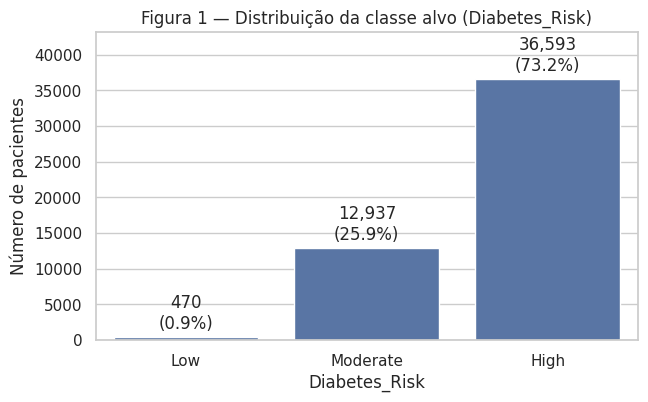

In [7]:
def label_bars(ax, labels=None, fmt: str = "{:,.0f}") -> None:
    for i, bar in enumerate(ax.patches):
        text = labels[i] if labels else fmt.format(bar.get_height())
        ax.annotate(text, (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")

def plot_grid(columns, draw_fn, ncols: int = 4, cell_size=(4.2, 3.2), **draw_kwargs) -> None:
    nrows = math.ceil(len(columns) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell_size[0] * ncols, cell_size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columns):
        draw_fn(col, ax, **draw_kwargs)
    for ax in axes[len(columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

# ----- Figura 1 -----
counts = target_labels.value_counts().reindex(CLASS_LIST)
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=counts.index, y=counts.values, color="#4C72B0")
label_bars(ax, [f"{n:,}\n({n / counts.sum():.1%})" for n in counts.values])
plt.title(f"Figura 1 — Distribuição da classe alvo ({TARGET})")
plt.xlabel(TARGET); plt.ylabel("Número de pacientes")
plt.ylim(0, counts.max() * 1.18)
plt.show()

In [8]:
n_low, n_mod, n_high = (int(counts[c]) for c in CLASS_LIST)
md(f"""
**Figura 1 — Adequação:** o gráfico de barras mostra o grau de desbalanceamento das classes e orienta a escolha de métricas e da estratificação.

- **Achado:** `High` = {pt(n_high / counts.sum() * 100, 1)}% ({pt(n_high, 0)}), `Moderate` = {pt(n_mod / counts.sum() * 100, 1)}% ({pt(n_mod, 0)}), `Low` = {pt(n_low / counts.sum() * 100, 1)}% ({pt(n_low, 0)}).
- **Evidência:** contagens e percentuais rotulados nas barras.
- **Relação e limite:** diz respeito ao objetivo analítico (classificação ordinal). A acurácia global seria enganosa (prever sempre `High` já acerta {pt(n_high / counts.sum() * 100, 1)}%), e com apenas {pt(n_low, 0)} casos `Low` (≈ {pt(n_low * TEST_SIZE, 0)} no teste de {pt(TEST_SIZE * 100, 0)}%) qualquer comparação que envolva essa classe nas hipóteses H1 a H4 tem baixa precisão.
""")


**Figura 1 — Adequação:** o gráfico de barras mostra o grau de desbalanceamento das classes e orienta a escolha de métricas e da estratificação.

- **Achado:** `High` = 73,2% (36.593), `Moderate` = 25,9% (12.937), `Low` = 0,9% (470).
- **Evidência:** contagens e percentuais rotulados nas barras.
- **Relação e limite:** diz respeito ao objetivo analítico (classificação ordinal). A acurácia global seria enganosa (prever sempre `High` já acerta 73,2%), e com apenas 470 casos `Low` (≈ 94 no teste de 20%) qualquer comparação que envolva essa classe nas hipóteses H1 a H4 tem baixa precisão.


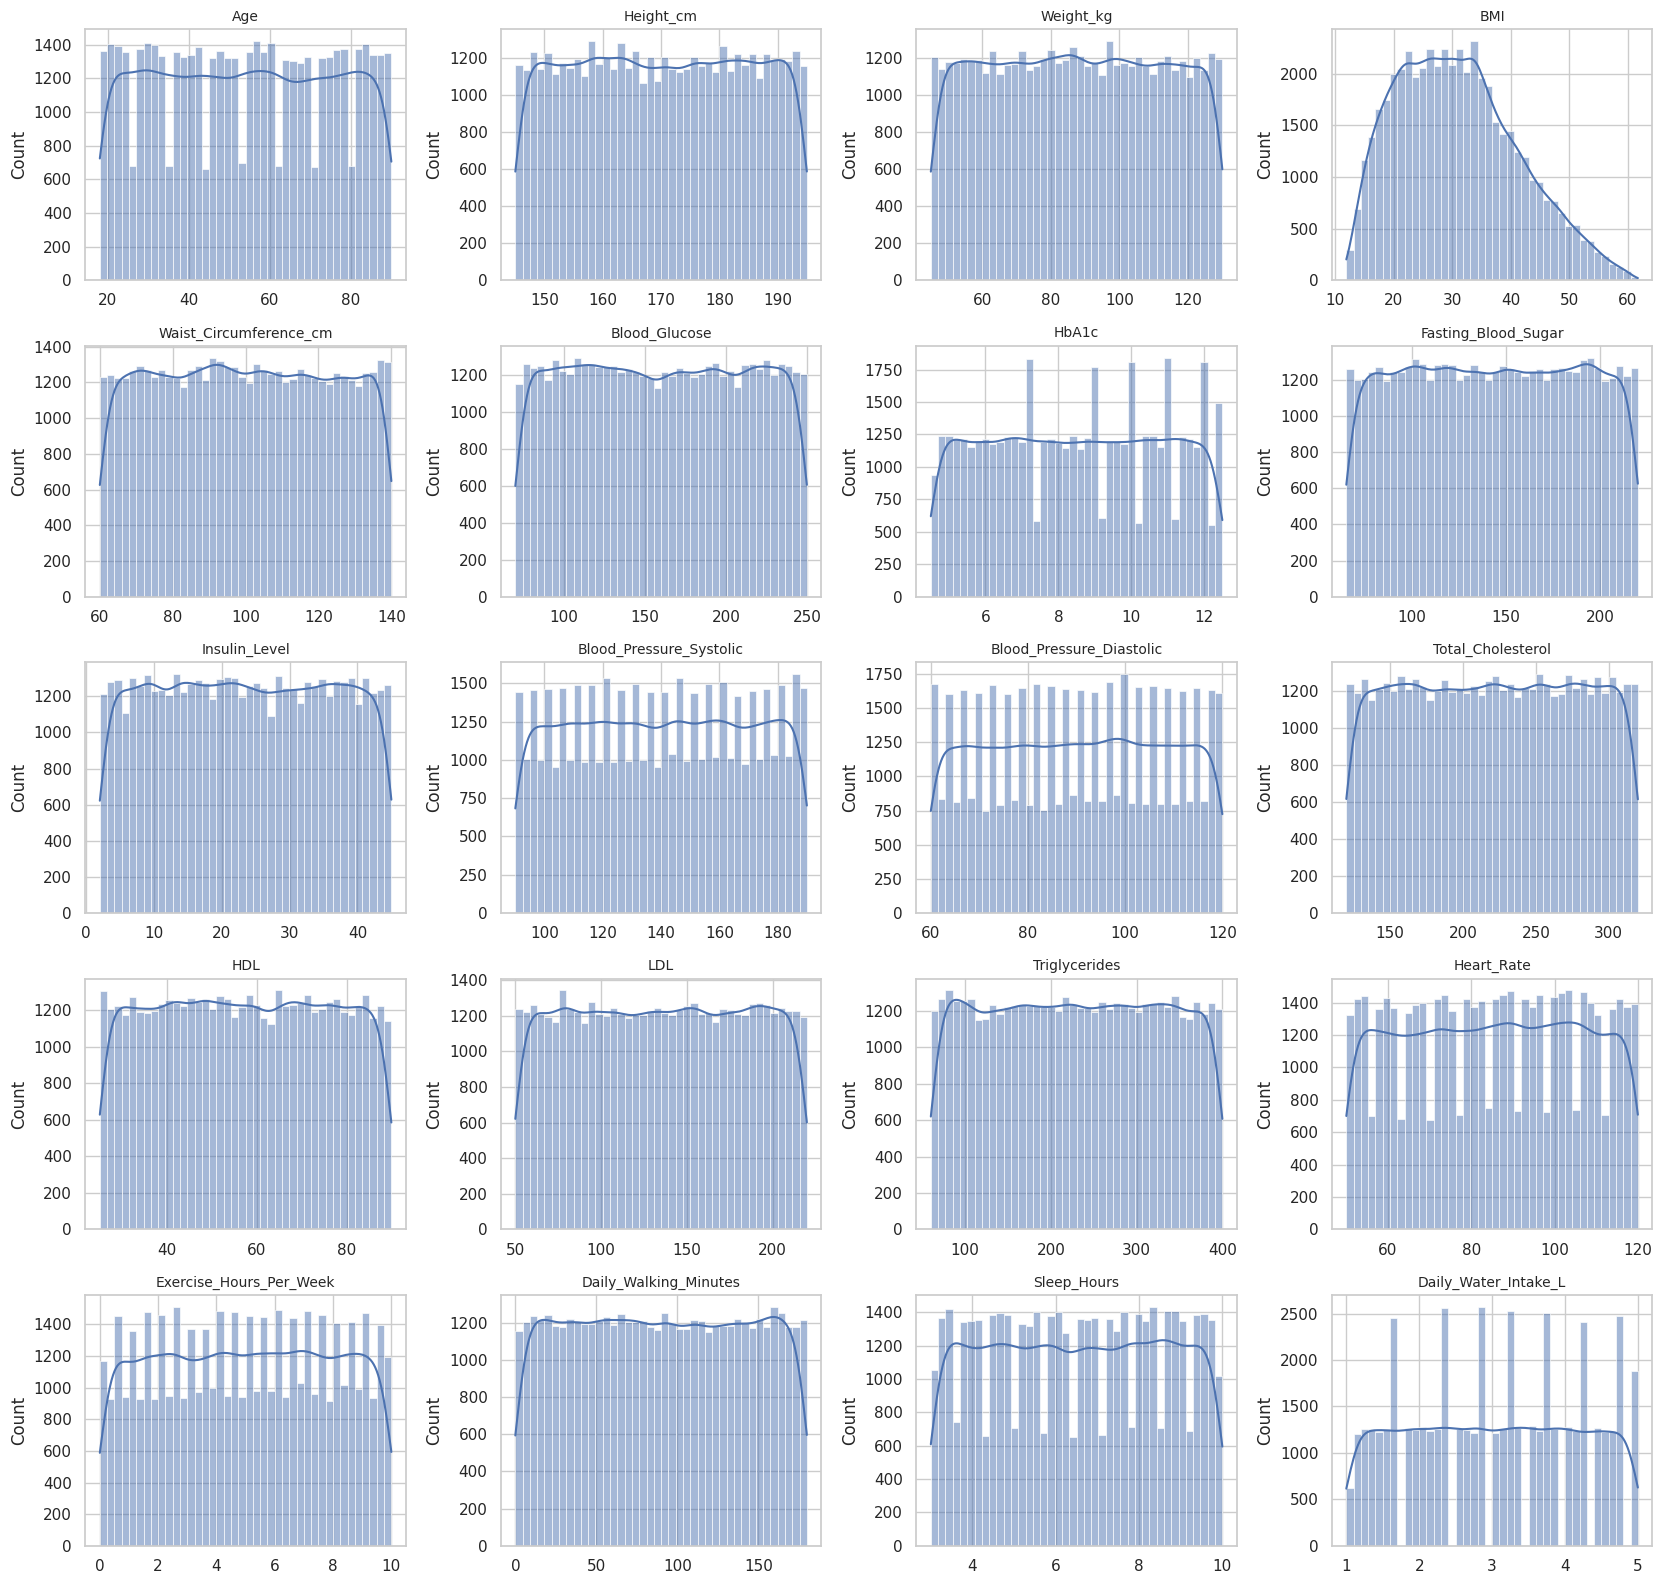

In [9]:
# ----- Figura 2 -----
def draw_histogram(col: str, ax, data: pd.DataFrame, bins: int) -> None:
    sns.histplot(data[col], kde=True, bins=bins, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")

plot_grid(continuous_cols, draw_histogram, data=df, bins=HIST_BINS)

In [10]:
planas = int((skew.abs() < 0.5).sum())
fortes = skew[skew.abs() >= 0.5]
maior = skew.abs().idxmax()
if len(fortes):
    txt_fortes = "Têm |assimetria| ≥ 0,5: " + ", ".join(f"`{i}` ({pt(v, 2)})" for i, v in fortes.items()) + "."
else:
    txt_fortes = "Nenhuma tem |assimetria| ≥ 0,5."
md(f"""
**Figura 2 — Adequação:** histogramas revelam assimetria, caudas longas e diferenças de escala entre os preditores contínuos.

- **Achado:** {planas} das {len(skew)} variáveis contínuas têm |assimetria| < 0,5, isto é, distribuição aproximadamente simétrica e plana. {txt_fortes} A maior assimetria absoluta é a de `{maior}` ({pt(skew[maior], 2)}); `BMI` tem assimetria {pt(skew['BMI'], 2)}.
- **Evidência:** tabela de assimetria (seção 3.2) e histogramas.
- **Relação e limite:** o padrão de distribuições planas é compatível com geração sintética. A ausência de assimetria forte justifica **não** aplicar transformação logarítmica; as escalas, porém, diferem muito entre variáveis, o que justifica as visões padronizada e normalizada (seção 4.4).
""")


**Figura 2 — Adequação:** histogramas revelam assimetria, caudas longas e diferenças de escala entre os preditores contínuos.

- **Achado:** 20 das 20 variáveis contínuas têm |assimetria| < 0,5, isto é, distribuição aproximadamente simétrica e plana. Nenhuma tem |assimetria| ≥ 0,5. A maior assimetria absoluta é a de `BMI` (0,43); `BMI` tem assimetria 0,43.
- **Evidência:** tabela de assimetria (seção 3.2) e histogramas.
- **Relação e limite:** o padrão de distribuições planas é compatível com geração sintética. A ausência de assimetria forte justifica **não** aplicar transformação logarítmica; as escalas, porém, diferem muito entre variáveis, o que justifica as visões padronizada e normalizada (seção 4.4).


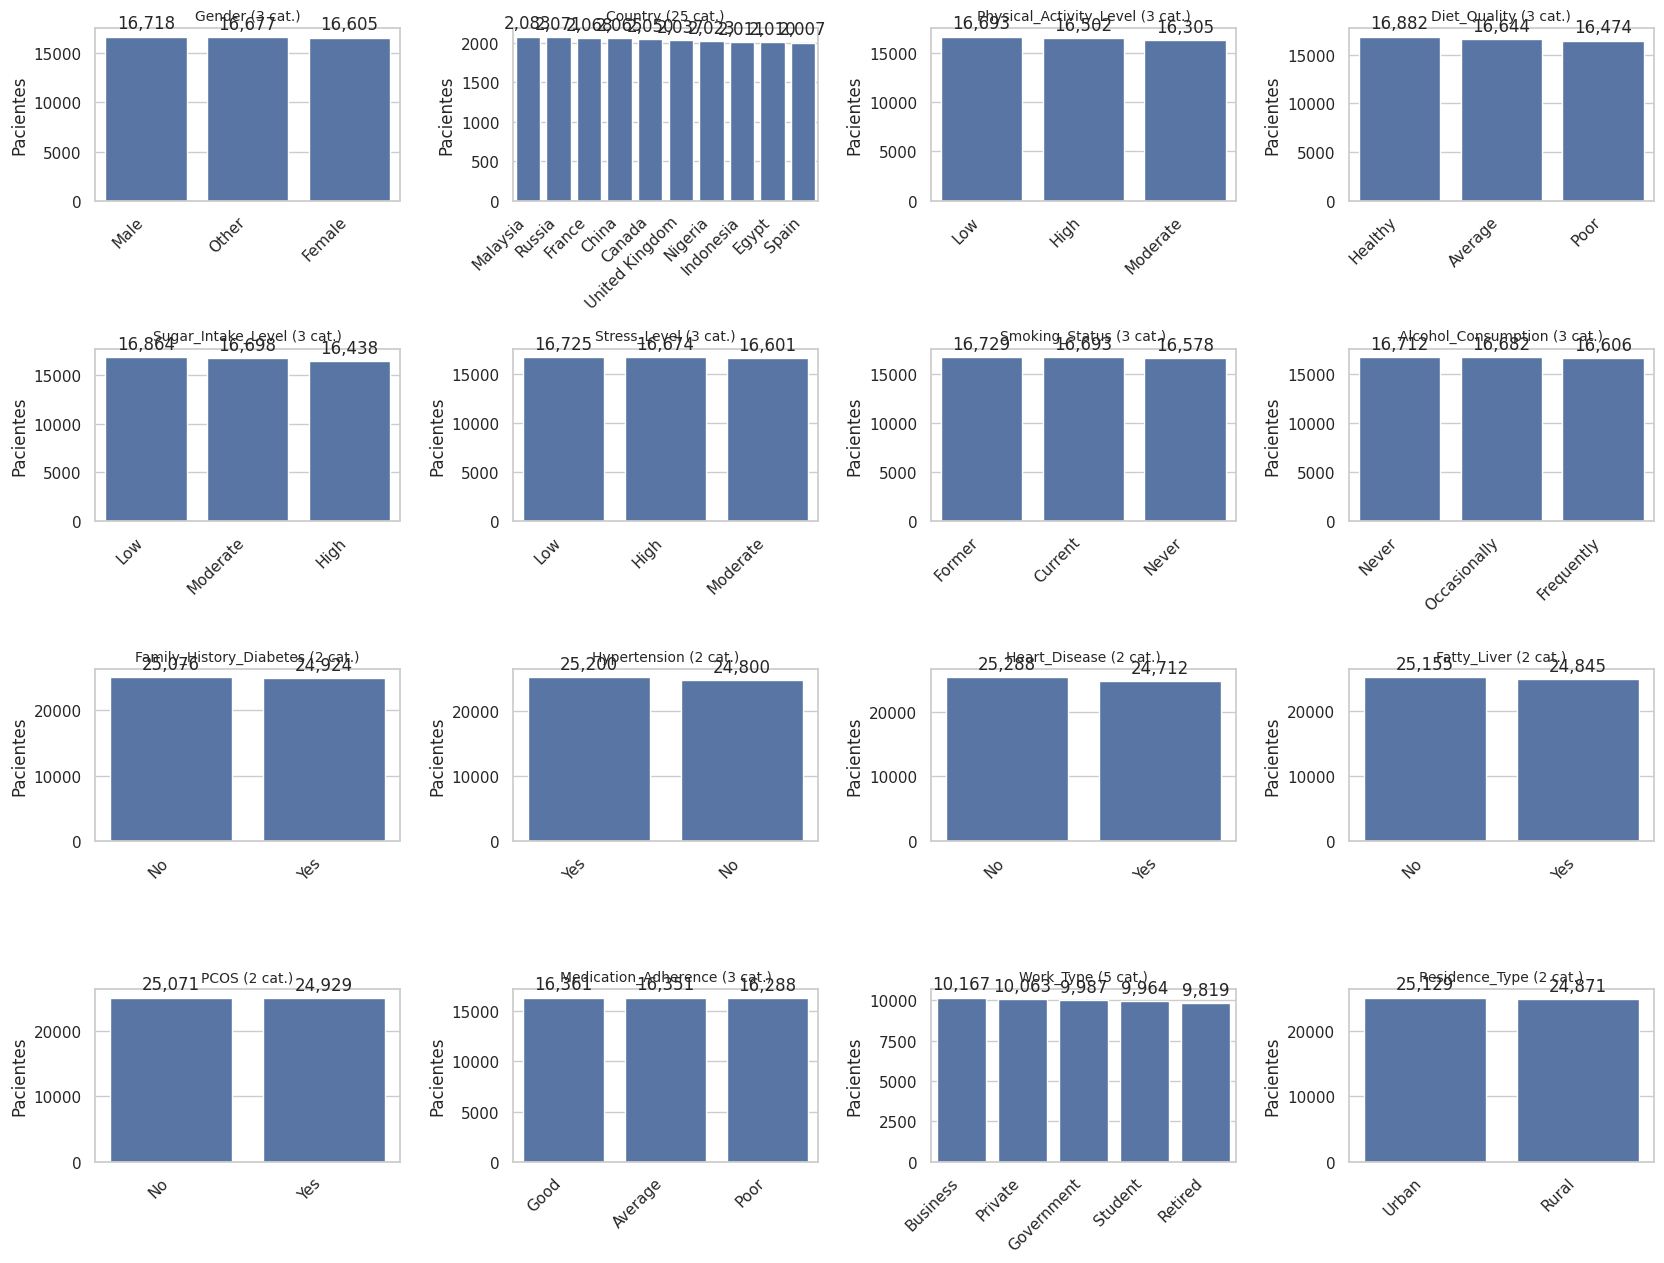

In [11]:
# ----- Figura 3 -----
def draw_countplot(col: str, ax, data: pd.DataFrame, max_categories: int) -> None:
    order = data[col].value_counts().index[:max_categories]
    sns.countplot(data=data[data[col].isin(order)], x=col, order=order, color="#4C72B0", ax=ax)
    label_bars(ax)
    ax.set_title(f"{col} ({data[col].nunique()} cat.)", fontsize=10)
    ax.set(xlabel="", ylabel="Pacientes")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

plot_grid(category_like_cols, draw_countplot, data=df, max_categories=MAX_CATEGORIES_PLOT)

In [12]:
v_min = cat_diag["menor_%"].idxmin()
md(f"""
**Figura 3 — Adequação:** gráficos de contagem expõem desproporções e categorias raras.

- **Achado:** em todas as {len(cat_diag)} variáveis categóricas/binárias a menor categoria tem no mínimo {pt(cat_diag['menor_%'].min(), 1)}% das linhas (menor valor em `{v_min}`); a maior categoria chega a {pt(cat_diag['maior_%'].max(), 1)}%.
- **Evidência:** tabela `cat_diag` (seção 3.2).
- **Relação e limite:** {'não há categorias raras (< 1%), portanto a codificação one-hot não gera colunas esparsas; ' if cat_diag['menor_%'].min() >= 1 else 'há categorias raras (< 1%), que o codificador agrupa (seção 4.4); '}distribuições tão equilibradas também são compatíveis com origem sintética. Não responde diretamente a H1–H4; apoia a decisão de codificação.
""")


**Figura 3 — Adequação:** gráficos de contagem expõem desproporções e categorias raras.

- **Achado:** em todas as 16 variáveis categóricas/binárias a menor categoria tem no mínimo 3,8% das linhas (menor valor em `Country`); a maior categoria chega a 50,6%.
- **Evidência:** tabela `cat_diag` (seção 3.2).
- **Relação e limite:** não há categorias raras (< 1%), portanto a codificação one-hot não gera colunas esparsas; distribuições tão equilibradas também são compatíveis com origem sintética. Não responde diretamente a H1–H4; apoia a decisão de codificação.


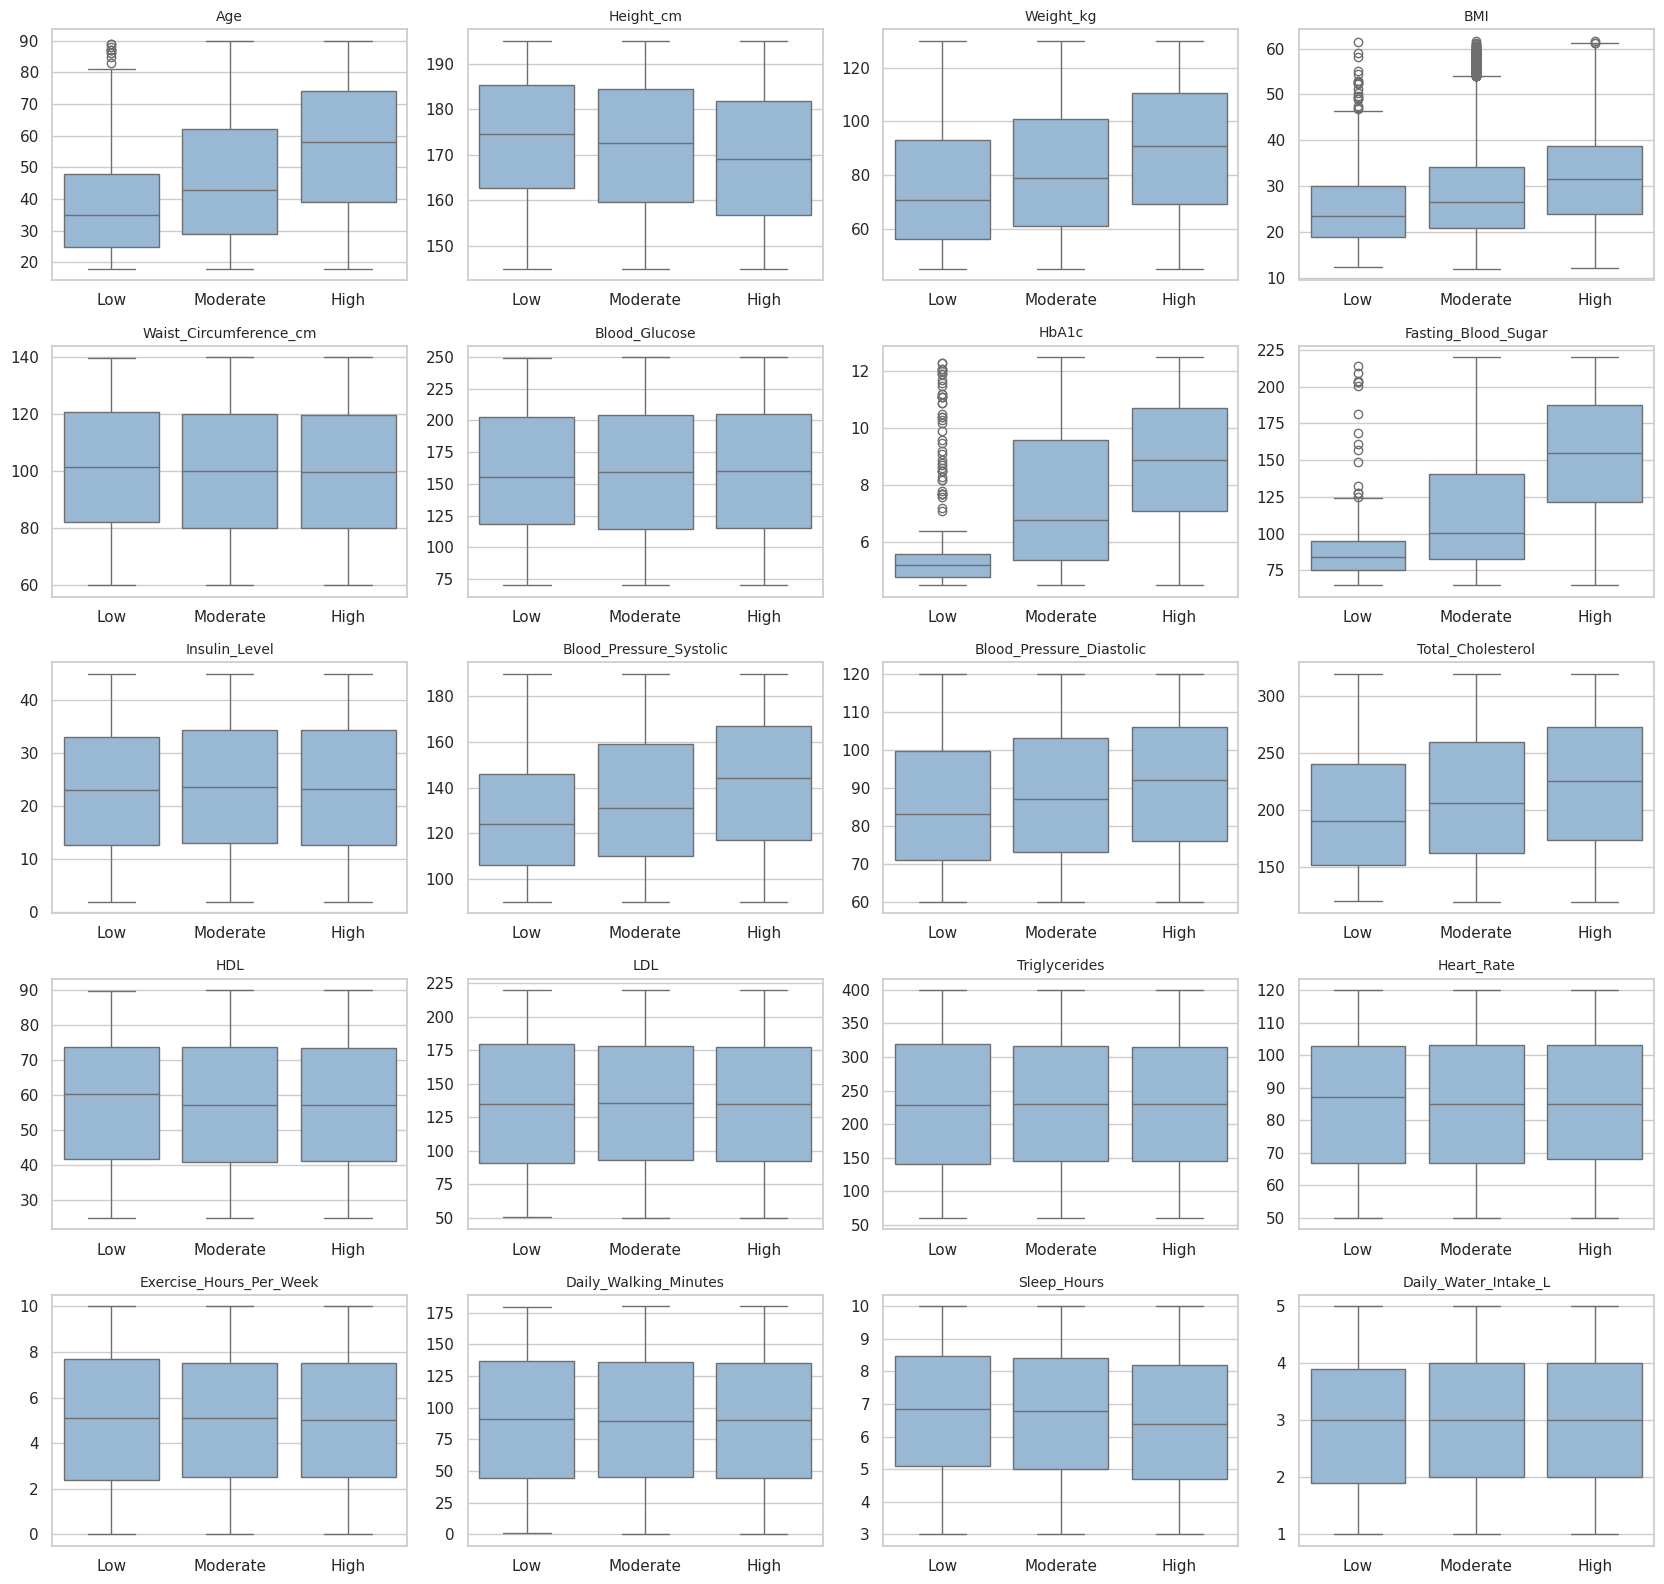

In [13]:
# ----- Figura 4 -----
def draw_boxplot_by_target(col: str, ax, data: pd.DataFrame, labels: pd.Series, class_order) -> None:
    sns.boxplot(x=labels, y=data[col], order=class_order, color="#8FB8DE", ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set(xlabel="", ylabel="")

plot_grid(continuous_cols, draw_boxplot_by_target, data=df, labels=target_labels, class_order=CLASS_LIST)

In [14]:
def linha_med(v: str) -> str:
    m = med.loc[v, CLASS_LIST]
    seq = " → ".join(f"{pt(m[c], 1)}" for c in CLASS_LIST)
    return f"`{v}`: {seq} ({'cresce' if cresce(v) else 'não cresce'} de forma estritamente monotônica)"

md(f"""
**Figura 4 — Adequação:** boxplots por classe comparam localização e dispersão de cada preditor contínuo entre os níveis de risco.

- **Achado (medianas Low → Moderate → High):**
  - {linha_med('Fasting_Blood_Sugar')}
  - {linha_med('HbA1c')}
  - {linha_med('Blood_Glucose')}
  - {linha_med('BMI')}
  - {linha_med('Age')}
- **Evidência:** tabela de medianas por classe (seção 3.2) e deslocamento das caixas.
- **Relação e limite:** relaciona-se a **H1** (glicemia) e **H2** (BMI e idade). Com apenas {pt(n_low, 0)} casos `Low`, a mediana dessa classe tem baixa precisão; boxplots mostram associação, não causalidade.
""")


**Figura 4 — Adequação:** boxplots por classe comparam localização e dispersão de cada preditor contínuo entre os níveis de risco.

- **Achado (medianas Low → Moderate → High):**
  - `Fasting_Blood_Sugar`: 84,2 → 100,6 → 155,0 (cresce de forma estritamente monotônica)
  - `HbA1c`: 5,2 → 6,8 → 8,9 (cresce de forma estritamente monotônica)
  - `Blood_Glucose`: 155,5 → 159,3 → 160,2 (cresce de forma estritamente monotônica)
  - `BMI`: 23,4 → 26,5 → 31,4 (cresce de forma estritamente monotônica)
  - `Age`: 35,0 → 43,0 → 58,0 (cresce de forma estritamente monotônica)
- **Evidência:** tabela de medianas por classe (seção 3.2) e deslocamento das caixas.
- **Relação e limite:** relaciona-se a **H1** (glicemia) e **H2** (BMI e idade). Com apenas 470 casos `Low`, a mediana dessa classe tem baixa precisão; boxplots mostram associação, não causalidade.


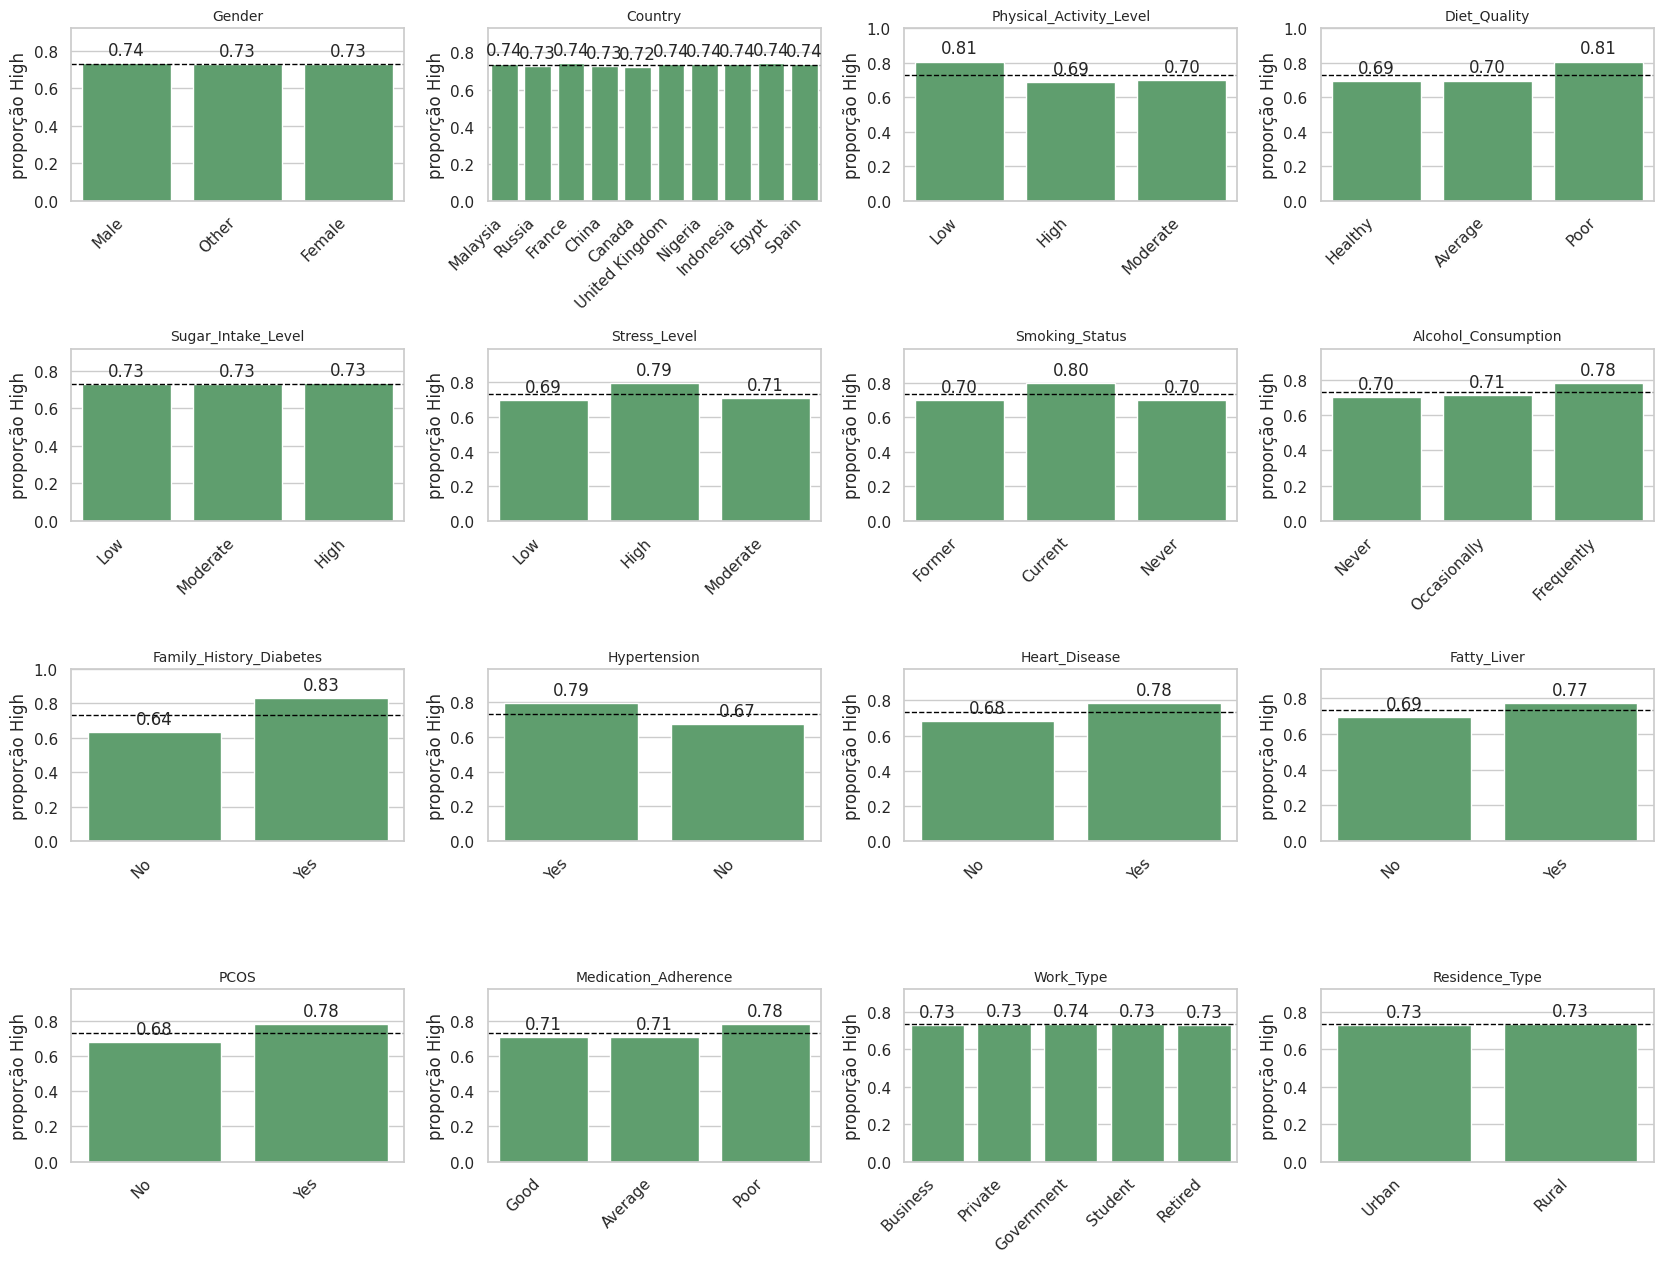

In [15]:
# ----- Figura 5 -----
def draw_rate_by_category(col: str, ax, data: pd.DataFrame, is_high: pd.Series, overall: float,
                          high_label: str, max_categories: int) -> None:
    top = data[col].value_counts().index[:max_categories]
    rates = is_high[data[col].isin(top)].groupby(data[col]).mean().reindex(top)
    sns.barplot(x=rates.index.astype(str), y=rates.values, color="#55A868", ax=ax)
    label_bars(ax, fmt="{:.2f}")
    ax.axhline(overall, color="black", linestyle="--", linewidth=1)
    ax.set_title(col, fontsize=10)
    ax.set(xlabel="", ylabel=f"proporção {high_label}", ylim=(0, min(1, rates.max() * 1.25)))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

plot_grid(category_like_cols, draw_rate_by_category, data=df, is_high=is_high_class,
          overall=overall_rate, high_label=HIGH_CLASS, max_categories=MAX_CATEGORIES_PLOT)

In [16]:
fh = (is_high_class.groupby(df["Family_History_Diabetes"]).mean() * 100)
fh_yes = fh["Yes"] if "Yes" in fh.index else fh.max()
fh_no = fh["No"] if "No" in fh.index else fh.min()
h4_txt = "; ".join(f"`{k}` = {pt(v, 1)}%" for k, v in h4.items())
md(f"""
**Figura 5 — Adequação:** a proporção da classe `High` por categoria, comparada à linha tracejada global ({pt(overall_rate * 100, 1)}%), mostra quais categorias elevam ou reduzem o risco.

- **Achado (H3):** a proporção de `High` é {pt(fh_yes, 1)}% com histórico familiar `Yes` e {pt(fh_no, 1)}% com `No` (diferença de {pt(fh_yes - fh_no, 1)} pontos percentuais).
- **Achado (H4):** proporção de `High` por `Physical_Activity_Level`: {h4_txt}.
- **Evidência:** barras e linha tracejada da figura; tabelas `h3` e `h4` (seção 3.2).
- **Relação e limite:** apoiam H3 e H4 apenas descritivamente. A associação não indica causalidade, e as demais categóricas devem ser lidas contra a linha de {pt(overall_rate * 100, 1)}%.
""")


**Figura 5 — Adequação:** a proporção da classe `High` por categoria, comparada à linha tracejada global (73,2%), mostra quais categorias elevam ou reduzem o risco.

- **Achado (H3):** a proporção de `High` é 82,9% com histórico familiar `Yes` e 63,5% com `No` (diferença de 19,4 pontos percentuais).
- **Achado (H4):** proporção de `High` por `Physical_Activity_Level`: `Low` = 80,7%; `Moderate` = 69,7%; `High` = 69,0%.
- **Evidência:** barras e linha tracejada da figura; tabelas `h3` e `h4` (seção 3.2).
- **Relação e limite:** apoiam H3 e H4 apenas descritivamente. A associação não indica causalidade, e as demais categóricas devem ser lidas contra a linha de 73,2%.


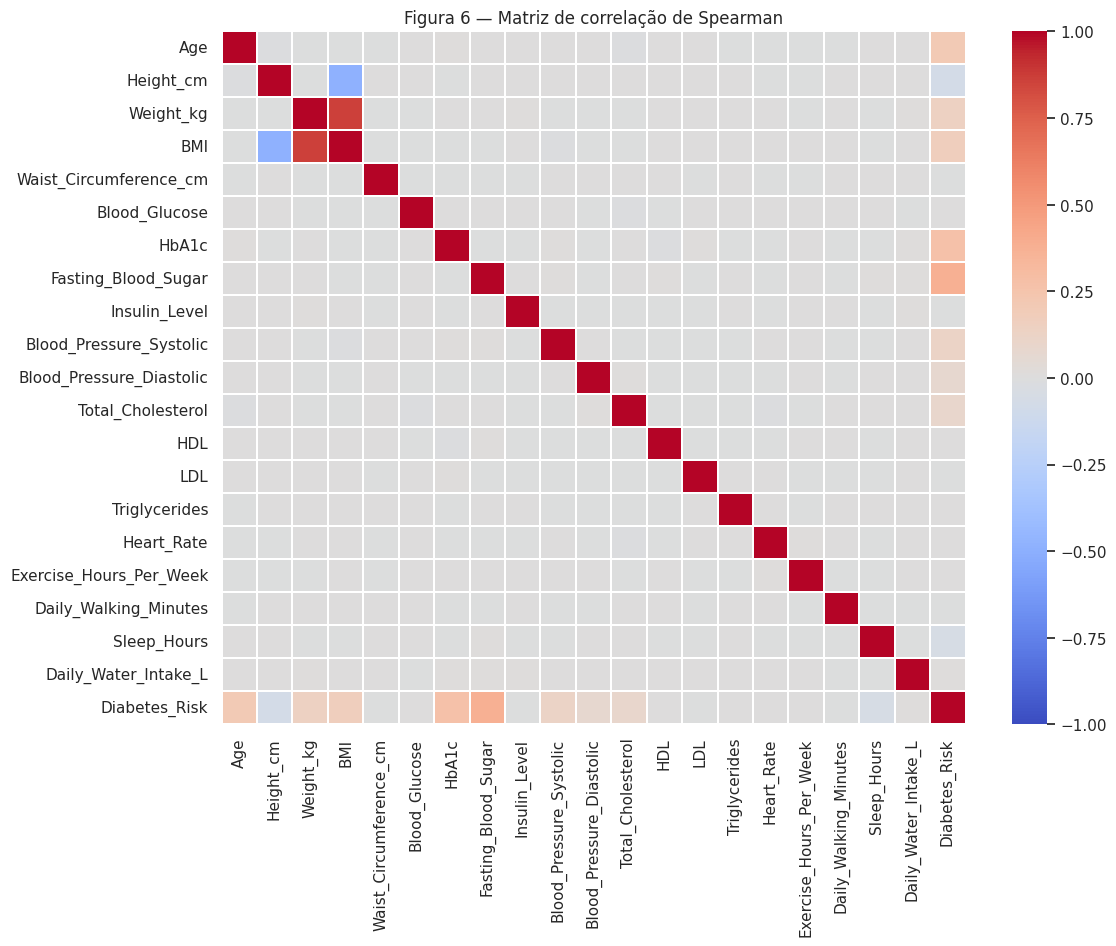

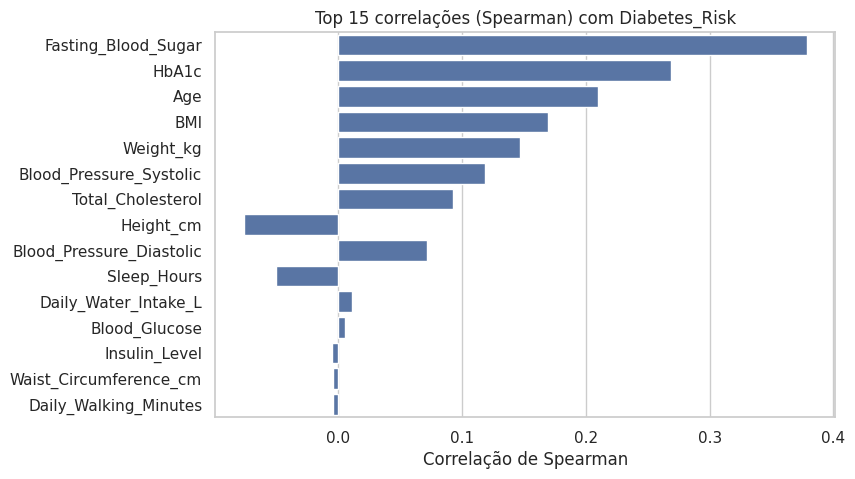

In [17]:
# ----- Figura 6 -----
numeric_cols_all = continuous_cols + binary_cols + [TARGET]
corr_matrix = df[numeric_cols_all].corr(method="spearman")

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.2,
            annot=len(numeric_cols_all) <= 12, fmt=".2f")
plt.title("Figura 6 — Matriz de correlação de Spearman")
plt.show()

target_corr = corr_matrix[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
top_corr = target_corr.head(TOP_N_CORRELATIONS)
plt.figure(figsize=(8, 5))
sns.barplot(x=top_corr.values, y=top_corr.index, color="#4C72B0")
plt.title(f"Top {TOP_N_CORRELATIONS} correlações (Spearman) com {TARGET}")
plt.xlabel("Correlação de Spearman"); plt.ylabel("")
plt.show()

In [18]:
pred_corr = corr_matrix.drop(index=TARGET, columns=TARGET).abs()
par = pred_corr.where(np.triu(np.ones(pred_corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
(pa, pb), pr = par.index[0], par.iloc[0]
t3 = target_corr.head(3)
md(f"""
**Figura 6 — Adequação:** a matriz de Spearman mede a associação monotônica entre preditores e o alvo ordinal e revela redundância entre preditores.

- **Achado:** as maiores correlações com o alvo são {', '.join(f'`{i}` (ρ = {pt(v, 2)}, {forca(v)})' for i, v in t3.items())}. `Blood_Glucose` tem ρ = {pt(target_corr['Blood_Glucose'], 3)} ({forca(target_corr['Blood_Glucose'])}); `BMI`, ρ = {pt(target_corr['BMI'], 2)}; `Age`, ρ = {pt(target_corr['Age'], 2)}.
- **Redundância entre preditores:** o par mais correlacionado é `{pa}` × `{pb}` (|ρ| = {pt(pr, 2)}); {'não há par com correlação alta (≥ 0,8)' if pr < 0.8 else 'há correlação alta (≥ 0,8), a considerar em modelos lineares'}.
- **Evidência:** valores da matriz e ranking de barras.
- **Relação e limite:** relaciona-se a **H1** e **H2**. A maior associação com o alvo é {forca(t3.iloc[0])}{'; isoladamente nenhum preditor separa bem as classes, o que sugere abordagens multivariadas na etapa de modelagem' if abs(t3.iloc[0]) < 0.5 else ''}. Correlação não implica causalidade.
""")


**Figura 6 — Adequação:** a matriz de Spearman mede a associação monotônica entre preditores e o alvo ordinal e revela redundância entre preditores.

- **Achado:** as maiores correlações com o alvo são `Fasting_Blood_Sugar` (ρ = 0,38, moderada), `HbA1c` (ρ = 0,27, fraca), `Age` (ρ = 0,21, fraca). `Blood_Glucose` tem ρ = 0,005 (desprezível); `BMI`, ρ = 0,17; `Age`, ρ = 0,21.
- **Redundância entre preditores:** o par mais correlacionado é `Weight_kg` × `BMI` (|ρ| = 0,86); há correlação alta (≥ 0,8), a considerar em modelos lineares.
- **Evidência:** valores da matriz e ranking de barras.
- **Relação e limite:** relaciona-se a **H1** e **H2**. A maior associação com o alvo é moderada; isoladamente nenhum preditor separa bem as classes, o que sugere abordagens multivariadas na etapa de modelagem. Correlação não implica causalidade.


## 4. Pré-processamento e decisões

### 4.1 Plano e prevenção de vazamento

O objetivo futuro é uma avaliação preditiva. Por isso, a partição **treino (80%) / teste (20%)** é feita de forma **estratificada** (semente fixa `RANDOM_STATE`) **antes** de qualquer etapa que aprenda parâmetros: imputação (mediana e moda), tratamento de extremos, escalonamento, discretização e codificação. Todos os parâmetros são ajustados (`fit`) apenas no treino e apenas aplicados (`transform`) no teste. A análise exploratória da seção 3 é descritiva e não alimenta nenhuma transformação; os limites de Tukey usados em D3 são calculados só no treino, e o limiar clínico de BMI (15) é fixo.

**Versões dos dados** (a visão de origem é preservada):

| Objeto | Descrição |
|---|---|
| `df_raw` | dados originais, nunca alterados |
| `df` | `df_raw` com o alvo codificado (0, 1, 2) — usado só na EDA |
| `df_clean` | sem identificador e sem colunas de vazamento (decisão D1) |
| `X_train`, `X_test`, `y_train`, `y_test` | partição 80/20 estratificada; BMI < 15 → ausente (decisão D3) |
| `datasets[visão]` | quatro visões processadas: `onehot`, `padronizado`, `normalizado`, `discretizado` |

In [19]:
EXCLUDED_COLS = [c for c in ID_COLS + LEAKAGE_COLS if c in df.columns]
df_clean = df.drop(columns=EXCLUDED_COLS).drop_duplicates().reset_index(drop=True)

X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
X_train, X_test = X_train.copy(), X_test.copy()

print(f"df_clean: {df_clean.shape} | X_train: {X_train.shape} | X_test: {X_test.shape}")
print("Nulos antes do pré-processamento — treino:", int(X_train.isna().sum().sum()),
      "| teste:", int(X_test.isna().sum().sum()))

df_clean: (50000, 37) | X_train: (40000, 36) | X_test: (10000, 36)
Nulos antes do pré-processamento — treino: 16690 | teste: 4120


### 4.2 D1 — Remoção de identificador e colunas com vazamento

**Evidência:** células abaixo (correlação e tabelas cruzadas com o alvo).

In [20]:
vaz = {}
for c in LEAKAGE_COLS:
    if pd.api.types.is_numeric_dtype(df_raw[c]):
        rho = df_raw[c].corr(df[TARGET], method="spearman")
        vaz[c] = f"Spearman com o alvo = {pt(rho, 3)}"
        print(c, "— Spearman com o alvo:", round(rho, 3))
    else:
        t = pd.crosstab(df_raw[c], target_labels, normalize="index")[CLASS_LIST].round(3)
        display(t)
        vaz[c] = f"a categoria mais pura tem {pt(t.max(axis=1).max() * 100, 1)}% numa única classe"
print("ID: nº de valores distintos =", df_raw[ID_COLS[0]].nunique(), "de", len(df_raw))

Diabetes_Risk_Score — Spearman com o alvo: 0.769


classe,Low,Moderate,High
AI_Health_Recommendation,,,
Annual Diabetes Screening,1.0,0.0,0.0
Balanced Diet,1.0,0.0,0.0
Begin Diabetes Management Plan,0.0,0.0,1.0
Consult Endocrinologist Immediately,0.0,0.0,1.0
Exercise Regularly,1.0,0.0,0.0
Healthy Diet Plan,0.0,1.0,0.0
Immediate Lifestyle Intervention,0.0,0.0,1.0
Increase Physical Activity,0.0,1.0,0.0
Maintain Healthy Lifestyle,1.0,0.0,0.0


classe,Low,Moderate,High
Doctor_Consultation_Needed,,,
No,0.117,0.883,0.000
Yes,0.001,0.211,0.788


ID: nº de valores distintos = 50000 de 50000


In [21]:
md(f"""
- **Necessidade e evidência:** `{'`, `'.join(ID_COLS)}` é identificador sem sentido preditivo ({pt(df_raw[ID_COLS[0]].nunique(), 0)} valores distintos em {pt(len(df_raw), 0)} linhas). As colunas `{'`, `'.join(LEAKAGE_COLS)}` são derivadas do próprio risco: {'; '.join(f'`{k}` → {v}' for k, v in vaz.items())}.
- **Alternativas consideradas:** (A) manter as colunas; (B) removê-las.
- **Escolha e justificativa:** (B). Um modelo que as use "aprenderia" a resposta (tautologia) e não generalizaria para o uso real, em que o risco ainda não é conhecido.
- **Verificação:** de {df_raw.shape[1]} colunas, restam {df_clean.shape[1]} em `df_clean` ({X.shape[1]} preditoras + alvo).
- **Limitação:** se o escore estivesse disponível no momento real de uso do modelo, a remoção poderia não ser necessária; a decisão depende de quando a predição ocorre.
""")


- **Necessidade e evidência:** `Patient_ID` é identificador sem sentido preditivo (50.000 valores distintos em 50.000 linhas). As colunas `Diabetes_Risk_Score`, `AI_Health_Recommendation`, `Doctor_Consultation_Needed` são derivadas do próprio risco: `Diabetes_Risk_Score` → Spearman com o alvo = 0,769; `AI_Health_Recommendation` → a categoria mais pura tem 100,0% numa única classe; `Doctor_Consultation_Needed` → a categoria mais pura tem 88,3% numa única classe.
- **Alternativas consideradas:** (A) manter as colunas; (B) removê-las.
- **Escolha e justificativa:** (B). Um modelo que as use "aprenderia" a resposta (tautologia) e não generalizaria para o uso real, em que o risco ainda não é conhecido.
- **Verificação:** de 41 colunas, restam 37 em `df_clean` (36 preditoras + alvo).
- **Limitação:** se o escore estivesse disponível no momento real de uso do modelo, a remoção poderia não ser necessária; a decisão depende de quando a predição ocorre.


### 4.3 D2 — Valores ausentes: exclusão de linhas × imputação

**Evidência do problema:** tabela de ausências da seção 3.1 e comparação abaixo (medida no conjunto de **treino**, antes da decisão D3).

In [22]:
cols_nulas = [c for c in continuous_cols if c in X_train.columns and X_train[c].isna().any()]
ref = X_train[cols_nulas]
A = X_train.dropna()                       # alternativa A: exclusão de linhas
B = ref.fillna(ref.median())               # alternativa B: imputação pela mediana do treino

comp_raw = pd.concat({"original (observados)": ref.agg(["mean", "std"]).T,
                      "A: exclusão": A[cols_nulas].agg(["mean", "std"]).T,
                      "B: imputação": B.agg(["mean", "std"]).T}, axis=1)
display(comp_raw.round(3))

cls = pd.DataFrame({"treino": y_train.value_counts().sort_index(),
                    "A: exclusão": y_train.loc[A.index].value_counts().sort_index()})
cls["perda_%"] = ((1 - cls["A: exclusão"] / cls["treino"]) * 100).round(1)
cls.index = [CLASS_NAMES[i] for i in cls.index]
display(cls)

original (observados)         A: exclusão         B: imputação        
                                         mean     std        mean     std         mean     std
Age                                    53.922  21.101      54.066  21.069       53.923  20.995
Height_cm                             169.981  14.453     169.952  14.449      169.976  14.017
Weight_kg                              87.432  24.513      87.484  24.518       87.424  23.763
Blood_Glucose                         160.051  52.087     159.506  52.020      160.050  51.579
HbA1c                                   8.489   2.316       8.496   2.312        8.489   2.270
Total_Cholesterol                     220.138  57.723     219.916  57.604      220.143  57.153
HDL                                    57.485  18.711      57.524  18.678       57.485  18.525
LDL                                   135.028  49.118     135.003  49.139      135.031  48.623
Triglycerides                         229.483  98.355     229.174  98.582      229.483  97.353
Exercise_Hours_Per_Week                 5.026   2.873       5.029   2.871        5.029   2.816
Daily_Walking_Minutes                  90.002  51.977      90.196  51.902       89.990  50.939
Sleep_Hours                             6.496   2.025       6.502   2.025        6.497   1.983

,treino,A: exclusão,perda_%
Low,376,249,33.8
Moderate,10350,6745,34.8
High,29274,19091,34.8


In [23]:
def desvio_max(alt: str, medida: str) -> float:
    return (comp_raw[(alt, medida)] - comp_raw[("original (observados)", medida)]).abs().max()

perda_total = (1 - len(A) / len(X_train)) * 100
n_cat_nulas = int(X_train[[c for c in text_cols(X_train)]].isna().any().sum())
md(f"""
- **Necessidade e evidência:** {len(miss_pos)} colunas têm ausências entre {pt(miss_pos['%'].min(), 2)}% e {pt(miss_pos['%'].max(), 2)}% (seção 3.1); {len(cols_nulas)} contínuas e {n_cat_nulas} categóricas com ausências no treino.
- **Alternativas consideradas:** (A) excluir linhas com qualquer ausência; (B) imputar mediana (contínuas) e moda (categóricas), com parâmetros aprendidos no treino.
- **Comparação efetiva** (tabelas `comp_raw` e `cls`, {len(cols_nulas)} contínuas com ausências): (A) reduziria o treino de {pt(len(X_train), 0)} para {pt(len(A), 0)} linhas (−{pt(perda_total, 1)}%) e a classe `Low` de {pt(cls.loc['Low', 'treino'], 0)} para {pt(cls.loc['Low', 'A: exclusão'], 0)} (−{pt(cls.loc['Low', 'perda_%'], 1)}%); `Moderate` perderia {pt(cls.loc['Moderate', 'perda_%'], 1)}% e `High`, {pt(cls.loc['High', 'perda_%'], 1)}%. O maior desvio de média em relação aos dados observados foi {pt(desvio_max('A: exclusão', 'mean'), 3)} em (A) e {pt(desvio_max('B: imputação', 'mean'), 3)} em (B); no desvio-padrão, {pt(desvio_max('A: exclusão', 'std'), 3)} em (A) e {pt(desvio_max('B: imputação', 'std'), 3)} em (B).
- **Escolha e justificativa:** (B). Preserva todas as linhas e a classe `Low`, já rara; {'além disso distorce menos a média do que a exclusão' if desvio_max('B: imputação', 'mean') <= desvio_max('A: exclusão', 'mean') else 'embora distorça a média um pouco mais do que a exclusão, o desvio é pequeno frente ao ganho de preservar as linhas'}.
- **Verificação:** 0 ausentes nas bases processadas (seção 4.6).
- **Limitação:** a imputação pela mediana reduz levemente a variância e ignora relações entre variáveis; o mecanismo de ausência é desconhecido, e a perda proporcional entre classes em (A) não prova que a ausência seja aleatória.
""")


- **Necessidade e evidência:** 14 colunas têm ausências entre 0,99% e 5,92% (seção 3.1); 12 contínuas e 2 categóricas com ausências no treino.
- **Alternativas consideradas:** (A) excluir linhas com qualquer ausência; (B) imputar mediana (contínuas) e moda (categóricas), com parâmetros aprendidos no treino.
- **Comparação efetiva** (tabelas `comp_raw` e `cls`, 12 contínuas com ausências): (A) reduziria o treino de 40.000 para 26.085 linhas (−34,8%) e a classe `Low` de 376 para 249 (−33,8%); `Moderate` perderia 34,8% e `High`, 34,8%. O maior desvio de média em relação aos dados observados foi 0,545 em (A) e 0,012 em (B); no desvio-padrão, 0,227 em (A) e 1,038 em (B).
- **Escolha e justificativa:** (B). Preserva todas as linhas e a classe `Low`, já rara; além disso distorce menos a média do que a exclusão.
- **Verificação:** 0 ausentes nas bases processadas (seção 4.6).
- **Limitação:** a imputação pela mediana reduz levemente a variância e ignora relações entre variáveis; o mecanismo de ausência é desconhecido, e a perda proporcional entre classes em (A) não prova que a ausência seja aleatória.


### 4.4 D3 — Valores extremos × erros de registro (BMI)

**Evidência do problema:** diagnóstico de Tukey (seção 3.2) e células abaixo, calculadas **no treino**.

In [24]:
tk = tukey_summary(X_train, ["BMI"])
display(tk)

erros_bmi_train = X_train["BMI"] < BMI_MIN_PLAUSIBLE
erros_bmi_test = X_test["BMI"] < BMI_MIN_PLAUSIBLE
print(f"BMI < {BMI_MIN_PLAUSIBLE} — treino: {int(erros_bmi_train.sum())} | teste: {int(erros_bmi_test.sum())}")
display(X_train.loc[erros_bmi_train, ["BMI", "Weight_kg", "Height_cm"]].head(15))

comp_bmi = pd.DataFrame({
    "com todos": X_train["BMI"].agg(["count", "mean", "median", "std", "min", "max"]),
    "sem BMI < 15": X_train.loc[~erros_bmi_train, "BMI"].agg(["count", "mean", "median", "std", "min", "max"]),
}).round(3)
display(comp_bmi)

# Decisão (C): valores implausíveis viram ausentes e serão imputados pela mediana do treino
X_train.loc[erros_bmi_train, "BMI"] = np.nan
X_test.loc[erros_bmi_test, "BMI"] = np.nan
print("BMI ausentes após D3 — treino:", int(X_train["BMI"].isna().sum()), "| teste:", int(X_test["BMI"].isna().sum()))

,abaixo,acima,outliers,%,lim_inf,lim_sup,min,max
BMI,0.0,23.0,23.0,0.06,0.05,60.45,11.9,61.7


BMI < 15.0 — treino: 1208 | teste: 287


,BMI,Weight_kg,Height_cm
2317,13.9,45.8,181.2
37275,13.8,51.1,192.7
45622,13.0,45.9,187.6
46556,14.1,45.7,180.2
13801,12.3,NaN,193.2
20237,14.5,46.8,179.7
13051,14.7,55.2,194.0
25514,13.9,52.0,193.2
6217,14.6,50.5,186.2
45202,13.8,49.2,189.1


,com todos,sem BMI < 15
count,40000.000,38792.000
mean,30.929,31.460
median,30.000,30.500
std,10.307,10.009
min,11.900,15.000
max,61.700,61.700


BMI ausentes após D3 — treino: 1208 | teste: 287


In [25]:
n_erro = int(erros_bmi_train.sum())
n_abaixo, n_acima = int(tk.loc["BMI", "abaixo"]), int(tk.loc["BMI", "acima"])
ant, dep = comp_bmi["com todos"], comp_bmi["sem BMI < 15"]
min_peso = X_train.loc[erros_bmi_train, "Weight_kg"].min() if n_erro else float("nan")
md(f"""
- **Necessidade e evidência:** no treino, o critério de Tukey marca {int(tk.loc['BMI', 'outliers'])} valores de `BMI` ({n_abaixo} abaixo e {n_acima} acima dos limites {pt(tk.loc['BMI', 'lim_inf'], 1)}–{pt(tk.loc['BMI', 'lim_sup'], 1)}). Desses, {n_erro} estão abaixo de {pt(BMI_MIN_PLAUSIBLE, 0)} (mínimo de {pt(ant['min'], 1)}), valor fisiologicamente implausível para adultos e tratado como **provável erro de registro**; os extremos altos são compatíveis com obesidade grave e plausíveis.
- **Alternativas consideradas:** (A) manter tudo; (B) remover as linhas marcadas; (C) manter os extremos plausíveis e transformar os valores < {pt(BMI_MIN_PLAUSIBLE, 0)} em ausentes, imputando-os com a mediana do treino.
- **Escolha e justificativa:** (C). Corrige o erro evidente sem perder linhas nem casos `Low`, e mantém a variabilidade real dos extremos altos. O limiar é fixo, definido por critério clínico, e portanto não gera vazamento.
- **Verificação** (`comp_bmi`): a média passa de {pt(ant['mean'], 2)} para {pt(dep['mean'], 2)} e o desvio-padrão, de {pt(ant['std'], 2)} para {pt(dep['std'], 2)}; o mínimo, de {pt(ant['min'], 1)} para {pt(dep['min'], 1)}. {'O efeito numérico sobre média e dispersão é pequeno: a decisão se sustenta mais por critério clínico e pela preservação das linhas do que pelo tamanho do efeito.' if abs(dep['mean'] - ant['mean']) < 0.1 * ant['std'] else 'O efeito sobre a média (' + pt(dep['mean'] - ant['mean'], 2) + ') e sobre o desvio-padrão justifica o tratamento além do critério clínico.'}
- **Limitação:** a regra IMC = peso/altura² não apresentou violações na seção 3.1, logo um BMI implausível implica que `Weight_kg` ou `Height_cm` também são implausíveis (menor peso entre os casos: {pt(min_peso, 1)} kg). Ao anular só o `BMI`, essas colunas permanecem como estão. O limiar 15 é uma escolha clínica, e valores entre 15 e o limite inferior de Tukey não foram auditados.
""")


- **Necessidade e evidência:** no treino, o critério de Tukey marca 23 valores de `BMI` (0 abaixo e 23 acima dos limites 0,1–60,5). Desses, 1208 estão abaixo de 15 (mínimo de 11,9), valor fisiologicamente implausível para adultos e tratado como **provável erro de registro**; os extremos altos são compatíveis com obesidade grave e plausíveis.
- **Alternativas consideradas:** (A) manter tudo; (B) remover as linhas marcadas; (C) manter os extremos plausíveis e transformar os valores < 15 em ausentes, imputando-os com a mediana do treino.
- **Escolha e justificativa:** (C). Corrige o erro evidente sem perder linhas nem casos `Low`, e mantém a variabilidade real dos extremos altos. O limiar é fixo, definido por critério clínico, e portanto não gera vazamento.
- **Verificação** (`comp_bmi`): a média passa de 30,93 para 31,46 e o desvio-padrão, de 10,31 para 10,01; o mínimo, de 11,9 para 15,0. O efeito numérico sobre média e dispersão é pequeno: a decisão se sustenta mais por critério clínico e pela preservação das linhas do que pelo tamanho do efeito.
- **Limitação:** a regra IMC = peso/altura² não apresentou violações na seção 3.1, logo um BMI implausível implica que `Weight_kg` ou `Height_cm` também são implausíveis (menor peso entre os casos: 45,0 kg). Ao anular só o `BMI`, essas colunas permanecem como estão. O limiar 15 é uma escolha clínica, e valores entre 15 e o limite inferior de Tukey não foram auditados.


### 4.5 Transformações e visões geradas

Quatro visões são geradas; cada uma existe por um uso futuro específico. Em todas: imputação (mediana para contínuas, moda para categóricas e binárias), codificação *one-hot* das categóricas (`drop="if_binary"`, categorias com frequência < 1% agrupadas) e parâmetros aprendidos apenas no treino. O alvo não é transformado (já codificado como 0, 1, 2 na ordem Low < Moderate < High).

| Visão | Transformação adicional | Uso futuro previsto | Por que existe |
|---|---|---|---|
| `onehot` | nenhuma | árvores e ensembles | não exigem escala |
| `padronizado` | média 0 e desvio 1 | regressão logística, SVM, k-NN | sensíveis à escala |
| `normalizado` | intervalo [0, 1] | redes neurais | entradas em faixa limitada |
| `discretizado` | 5 faixas por quantis (*one-hot*) | Naive Bayes, regras | interpretação por faixas |

Não foram aplicados PCA, balanceamento de classes nem criação de variáveis: não há necessidade demonstrada (correlações entre preditores baixas, seção 3.3) e o balanceamento, quando usado, deve ocorrer apenas no treino durante a modelagem.

In [26]:
cat_cols_model = text_cols(X_train)
bin_cols_model = [c for c in X_train.select_dtypes(include="number").columns if X_train[c].nunique(dropna=True) <= 2]
cont_cols_model = [c for c in X_train.select_dtypes(include="number").columns if c not in bin_cols_model]

def build_preprocessor(view: str) -> ColumnTransformer:
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if view == "padronizado":
        num_steps.append(("scaler", StandardScaler()))
    elif view == "normalizado":
        num_steps.append(("scaler", MinMaxScaler()))
    elif view == "discretizado":
        num_steps.append(("bins", KBinsDiscretizer(n_bins=N_DISCRETIZATION_BINS,
                                                   encode="onehot-dense", strategy="quantile")))
    cat_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="if_binary", min_frequency=MIN_CATEGORY_FREQUENCY,
                                 handle_unknown="infrequent_if_exist", sparse_output=False))])
    bin_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))])
    return ColumnTransformer([
        ("cont", Pipeline(num_steps), cont_cols_model),
        ("bin", bin_pipeline, bin_cols_model),
        ("cat", cat_pipeline, cat_cols_model)], verbose_feature_names_out=False).set_output(transform="pandas")

VIEWS = ["onehot", "padronizado", "normalizado", "discretizado"]
datasets = {}
OUTPUT_DIR.mkdir(exist_ok=True)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for v in VIEWS:
        prep = build_preprocessor(v)
        datasets[v] = {"train": prep.fit_transform(X_train),   # ajuste só no treino
                       "test": prep.transform(X_test)}          # teste apenas transformado
        for split, target_vec in (("train", y_train), ("test", y_test)):
            tabela = datasets[v][split].assign(**{TARGET: target_vec.to_numpy()})
            tabela.to_csv(OUTPUT_DIR / f"diabetes_{v}_{split}.csv.gz", index=False, float_format="%.6g")

print(f"{len(VIEWS) * 2} arquivos salvos em '{OUTPUT_DIR}/'.")

8 arquivos salvos em 'dados_processados/'.


### 4.6 Verificações antes e depois

In [27]:
print("ANTES — X:", X.shape, "| treino:", X_train.shape, "| teste:", X_test.shape)
print("Nulos antes (treino):", int(X_train.isna().sum().sum()), "| (teste):", int(X_test.isna().sum().sum()))

check = pd.DataFrame({
    v: {"treino": d["train"].shape, "teste": d["test"].shape,
        "nulos": int(d["train"].isna().sum().sum() + d["test"].isna().sum().sum())}
    for v, d in datasets.items()}).T
display(check)

assert set(X_train.index).isdisjoint(X_test.index), "Vazamento de índices entre treino e teste!"
assert all(check["nulos"] == 0), "Há valores ausentes após o pré-processamento!"

prop = pd.DataFrame({"treino": y_train.map(CLASS_NAMES).value_counts(normalize=True),
                     "teste": y_test.map(CLASS_NAMES).value_counts(normalize=True)}).reindex(CLASS_LIST)
display((prop * 100).round(2))

pad = datasets["padronizado"]["train"][cont_cols_model]
nor = datasets["normalizado"]["train"][cont_cols_model]
nor_te = datasets["normalizado"]["test"][cont_cols_model]
print(f"Padronizado (treino): |média| máx = {pad.mean().abs().max():.2e} | desvio entre {pad.std().min():.3f} e {pad.std().max():.3f}")
print(f"Normalizado (treino): min = {nor.min().min():.3f} | máx = {nor.max().max():.3f}")
print(f"Normalizado (teste, parâmetros do treino): min = {nor_te.min().min():.3f} | máx = {nor_te.max().max():.3f}")

ANTES — X: (50000, 36) | treino: (40000, 36) | teste: (10000, 36)
Nulos antes (treino): 17898 | (teste): 4407


,treino,teste,nulos
onehot,"(40000, 80)","(10000, 80)",0
padronizado,"(40000, 80)","(10000, 80)",0
normalizado,"(40000, 80)","(10000, 80)",0
discretizado,"(40000, 160)","(10000, 160)",0


,treino,teste
Diabetes_Risk,,
Low,0.94,0.94
Moderate,25.87,25.87
High,73.18,73.19


Padronizado (treino): |média| máx = 2.16e-15 | desvio entre 1.000 e 1.000
Normalizado (treino): min = 0.000 | máx = 1.000
Normalizado (teste, parâmetros do treino): min = 0.000 | máx = 1.000


In [28]:
ncol = check["treino"].map(lambda s: s[1])
md(f"""
**Interpretação (verificações).**

- **Integridade:** treino e teste têm, respectivamente, {pt(len(X_train), 0)} e {pt(len(X_test), 0)} linhas ({pt(len(X_train) / len(X) * 100, 0)}% / {pt(len(X_test) / len(X) * 100, 0)}%), e nenhuma linha foi perdida ({pt(X.shape[0], 0)} em `df_clean`). Os índices de treino e teste são disjuntos (verificado por `assert`).
- **Ausências:** {pt(X_train.isna().sum().sum(), 0)} valores ausentes no treino antes do tratamento (incluindo os BMI < 15 anulados em D3) e **0** em todas as visões depois.
- **Classes:** a proporção em treino e teste é praticamente idêntica ({' / '.join(f'{pt(prop.loc[c, "treino"] * 100, 1)}%' for c in CLASS_LIST)} no treino e {' / '.join(f'{pt(prop.loc[c, "teste"] * 100, 1)}%' for c in CLASS_LIST)} no teste), confirmando a estratificação.
- **Escalas:** na visão padronizada, |média| máxima = {pad.mean().abs().max():.1e} e desvio entre {pt(pad.std().min(), 3)} e {pt(pad.std().max(), 3)}; na normalizada, o treino vai de {pt(nor.min().min(), 2)} a {pt(nor.max().max(), 2)}. No **teste**, a normalizada pode ultrapassar [0, 1] ({pt(nor_te.min().min(), 3)} a {pt(nor_te.max().max(), 3)}) porque usa os parâmetros do treino — comportamento esperado e que confirma que o teste não influenciou o ajuste.
- **Número de colunas por visão:** {', '.join(f'`{v}` = {n}' for v, n in ncol.items())}.
""")


**Interpretação (verificações).**

- **Integridade:** treino e teste têm, respectivamente, 40.000 e 10.000 linhas (80% / 20%), e nenhuma linha foi perdida (50.000 em `df_clean`). Os índices de treino e teste são disjuntos (verificado por `assert`).
- **Ausências:** 17.898 valores ausentes no treino antes do tratamento (incluindo os BMI < 15 anulados em D3) e **0** em todas as visões depois.
- **Classes:** a proporção em treino e teste é praticamente idêntica (0,9% / 25,9% / 73,2% no treino e 0,9% / 25,9% / 73,2% no teste), confirmando a estratificação.
- **Escalas:** na visão padronizada, |média| máxima = 2.2e-15 e desvio entre 1,000 e 1,000; na normalizada, o treino vai de 0,00 a 1,00. No **teste**, a normalizada pode ultrapassar [0, 1] (0,000 a 1,000) porque usa os parâmetros do treino — comportamento esperado e que confirma que o teste não influenciou o ajuste.
- **Número de colunas por visão:** `onehot` = 80, `padronizado` = 80, `normalizado` = 80, `discretizado` = 160.


## 5. Respostas e conclusão

Os números da tabela abaixo são calculados a partir das saídas das seções 3.2 e 3.3 (Spearman, medianas, proporções, qui-quadrado), de modo que texto e evidência não divergem.

In [29]:
def rho(v): return spearman_corr[v]

# H1
gl = ["Fasting_Blood_Sugar", "HbA1c", "Blood_Glucose"]
ok_h1 = [v for v in gl if cresce(v) and rho(v) >= 0.1]
v_h1 = "Confirmada" if len(ok_h1) == 3 else "Parcialmente confirmada" if ok_h1 else "Não confirmada"
e_h1 = "; ".join(f"`{v}` ρ = {pt(rho(v), 2)} ({forca(rho(v))})" for v in gl)
i_h1 = "Nem todos os indicadores acompanham o risco; glicose pontual × HbA1c (média de ~3 meses) são medidas distintas" if len(ok_h1) < 3 else "Associação fraca/moderada; base sintética"

# H2
ok_h2 = [v for v in ["BMI", "Age"] if cresce(v) and rho(v) >= 0.1]
f_h2 = forca(min(rho("BMI"), rho("Age")))
v_h2 = (f"Confirmada ({f_h2})" if len(ok_h2) == 2 else "Parcialmente confirmada" if ok_h2 else "Não confirmada")
e_h2 = "; ".join(f"`{v}` ρ = {pt(rho(v), 2)}" for v in ["BMI", "Age"])

# H3
v_h3 = "Confirmada" if (fh_yes > fh_no and p_chi < 0.05) else "Não confirmada"
e_h3 = (f"`High` = {pt(fh_yes, 1)}% (Yes) × {pt(fh_no, 1)}% (No); χ² = {pt(chi2, 1)}, p = {p_chi:.1e}, V de Cramér = {pt(v_cramer, 3)}")

# H4
grad = bool(np.all(np.diff(h4.to_numpy()) < 0))
ex_dec = bool(np.all(np.diff(ex_med.to_numpy()) < 0))
v_h4 = "Confirmada" if (grad and ex_dec) else "Parcialmente confirmada" if (grad or ex_dec or h4.iloc[0] > h4.iloc[-1]) else "Não confirmada"
e_h4 = (f"% `High` por nível de atividade ({', '.join(f'{k}: {pt(v, 1)}' for k, v in h4.items())}); "
        f"mediana de horas/semana por classe ({' → '.join(pt(ex_med[c], 1) for c in CLASS_LIST)})")

md(f"""
| Hipótese | Resposta apoiada pelos dados | Evidência e localização | O que permanece incerto |
|---|---|---|---|
| **H1** | {v_h1} | {e_h1}. Seções 3.2, 3.3 (Figuras 4 e 6) | {i_h1} |
| **H2** | {v_h2} | {e_h2}; medianas {'crescentes' if len(ok_h2) == 2 else 'nem sempre crescentes'} por classe. Figuras 4 e 6 | Efeito individual pequeno; só {pt(n_low, 0)} casos `Low` |
| **H3** | {v_h3} | {e_h3}. Figura 5 | Associação, não causalidade; base sintética |
| **H4** | {v_h4} | {e_h4}. Figura 5 e seção 3.2 | Medidas de atividade pouco granulares; associação, não causalidade |

*"Significativo" só é usado em H3, onde há teste (qui-quadrado). Nas demais, a força é descrita pelo valor de ρ.*
""")


| Hipótese | Resposta apoiada pelos dados | Evidência e localização | O que permanece incerto |
|---|---|---|---|
| **H1** | Parcialmente confirmada | `Fasting_Blood_Sugar` ρ = 0,38 (moderada); `HbA1c` ρ = 0,27 (fraca); `Blood_Glucose` ρ = 0,01 (desprezível). Seções 3.2, 3.3 (Figuras 4 e 6) | Nem todos os indicadores acompanham o risco; glicose pontual × HbA1c (média de ~3 meses) são medidas distintas |
| **H2** | Confirmada (fraca) | `BMI` ρ = 0,17; `Age` ρ = 0,21; medianas crescentes por classe. Figuras 4 e 6 | Efeito individual pequeno; só 470 casos `Low` |
| **H3** | Confirmada | `High` = 82,9% (Yes) × 63,5% (No); χ² = 2.439,8, p = 0.0e+00, V de Cramér = 0,221. Figura 5 | Associação, não causalidade; base sintética |
| **H4** | Parcialmente confirmada | % `High` por nível de atividade (Low: 80,7, Moderate: 69,7, High: 69,0); mediana de horas/semana por classe (5,1 → 5,1 → 5,0). Figura 5 e seção 3.2 | Medidas de atividade pouco granulares; associação, não causalidade |

*"Significativo" só é usado em H3, onde há teste (qui-quadrado). Nas demais, a força é descrita pelo valor de ρ.*


### Limitações e próximos passos

**Limitações dos dados e da análise:**

1. A base parece **sintética** (distribuições planas, incoerências clínicas entre variáveis, alta proporção de `High`), o que limita a validade externa.
2. A classe `Low` tem poucos casos, o que torna imprecisas as comparações que a envolvem.
3. O **mecanismo de ausência é desconhecido**; a imputação por mediana é uma escolha simples e reduz levemente a variância.
4. As regras clínicas de consistência são **heurísticas**; os registros incoerentes foram mantidos.
5. O limiar de BMI (15) é clínico, não estatístico, e peso e altura dos casos anulados não foram corrigidos.
6. Todas as associações são **descritivas** e não causais; o dicionário de algumas variáveis foi inferido do nome da coluna.

**Próximos passos:** treinar modelos de classificação ordinal/multiclasse (por exemplo, regressão logística ordinal e *gradient boosting*) sobre as quatro visões, com validação cruzada estratificada e métricas robustas ao desbalanceamento (F1 macro, recall por classe, kappa ponderado); avaliar ponderação de classes **apenas no treino**; e, se houver acesso, validar em dados reais.

## Referências

- Kaggle. *Diabetes Risk Prediction Dataset (50K Patients)*. Disponível em: https://www.kaggle.com/datasets?search=Diabetes+Risk+Prediction+Dataset+50K+Patients. Acesso em: novembro de 2026. Cópia usada: https://github.com/renatobacha/MVP-AnalisedeDadosPUCRIO.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, 51–56.
- Harris, C. R. et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362.
- Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261–272.
- Hunter, J. D. (2007). Matplotlib: A 2D Graphics Environment. *Computing in Science & Engineering*, 9(3), 90–95.
- Waskom, M. (2021). seaborn: statistical data visualization. *Journal of Open Source Software*, 6(60), 3021.
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
- Material e template da disciplina (PUC-Rio).

## Declaração de uso de IA

Declaro que utilizei ferramentas de IA generativa como apoio técnico e editorial: **Gemini** para formatação de código Python, estruturação de blocos textuais e padronização do template da disciplina; e **Claude (Anthropic)** para revisar o notebook frente ao enunciado, sugerir correções de código e reorganizar as seções e textos de interpretação. O problema, a escolha da base, as hipóteses e as decisões foram definidos por mim; revisei o conteúdo e executei o notebook completo no Google Colab, e sou responsável pelo resultado final.

## 6. Checklist de entrega

| Item | Requisito | Localização no notebook | Não aplicabilidade |
|---|---|---|---|
| 1 | Problema, unidade de observação, pelo menos duas perguntas e objetivo analítico | Seção 1 (1.1 e 1.2) | — |
| 2 | Origem, versão/período, condições de uso, recortes e dicionário das variáveis | Seção 2 (2.1 a 2.3) | — |
| 3 | Dimensões, tipos, inspeção inicial e estatísticas adequadas | Seção 3.1 | — |
| 4 | Ausências, duplicidades, inconsistências e valores extremos | Seções 3.1 e 3.2 | — |
| 5 | Distribuições e relações relevantes, incluindo classes do alvo | Seções 3.2 e 3.3 (Figuras 1 a 6) | — |
| 6 | Interpretações após as figuras, com evidências e limites | Seção 3.3 | — |
| 7 | Decisões D1 a D3 e comparação efetiva entre alternativas | Seções 4.2, 4.3 (comparação A × B) e 4.4 | — |
| 8 | Transformações adequadas ou manutenção justificada, com verificações antes/depois | Seções 4.5 e 4.6 | — |
| 9 | Divisão dos dados e prevenção de vazamento | Seções 4.1 e 4.5 (partição estratificada com semente fixa; `fit` só no treino) | — |
| 10 | Respostas às perguntas, limitações e próximos passos | Seção 5 | — |
| 11 | Template adaptado, dados disponíveis, dependências indicadas, execução completa testada e link do Colab | Cabeçalho, seção 2.2 (versões), `README.md`, `requirements.txt` e repositório GitHub | — |
| 12 | Referências e declaração de uso de IA | Seções Referências e Declaração de uso de IA | — |